
# ❄️ Korean Beauty Product Customer Reviews Analysis

## Project Overview

This project focuses on analyzing customer reviews of Korean beauty and skincare products.
The objective is to understand customer satisfaction, product performance, skin type preferences,
and customer feedback through data analysis and Natural Language Processing (NLP).

## Project Objectives

1. Product Rating Analysis
2. Skin Type Analysis
3. Customer Satisfaction Analysis
3. Product Comparison Analysis
4. Korean Review Translation
5. Sentiment Analysis
6. Negative Review Analysis
7. Korean Keyword Analysis
8. Final Business Insights

## Dataset Information

Dataset: Korean Beauty Product Customer Reviews

Source: Original customer review dataset.

Main Columns:
- product_name
- rating
- skin_type
- review
- cleaned_review
- sentiment

## Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Korean NLP
- Machine Learning



In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing
import re
import unicodedata

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
df = pd.read_csv("/content/korean_beauty_reviews_cleaned.csv")
print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:
print("Dataset Shape:", df.shape)
print("Total Reviews:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset Shape: (92590, 7)
Total Reviews: 92590
Total Columns: 7


In [6]:
df.head()

,source_id,product_name,rating,skin_type,review,cleaned_review,sentiment
0,1,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Positive
1,2,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...","👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...",Positive
2,3,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름...,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...,Positive
3,4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,지성,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,Positive
4,5,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),5,복합성,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...","닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...",Positive


In [7]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['source_id', 'product_name', 'rating', 'skin_type', 'review', 'cleaned_review', 'sentiment']


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92590 entries, 0 to 92589
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   source_id       92590 non-null  int64 
 1   product_name    92590 non-null  object
 2   rating          92590 non-null  int64 
 3   skin_type       92590 non-null  object
 4   review          92590 non-null  object
 5   cleaned_review  92590 non-null  object
 6   sentiment       92590 non-null  object
dtypes: int64(2), object(5)
memory usage: 4.9+ MB



# PART 1: PRODUCT RATING ANALYSIS

## 1.1 Objective

To identify the highest-rated and lowest-rated Korean beauty products based on customer ratings.

## Business Questions

1. Which products have the highest average ratings?
2. Which products receive the most reviews?
3. Which products have the lowest average ratings?



In [9]:
product_ratings = df.groupby("product_name").agg(
    average_rating=("rating", "mean"),
    total_reviews=("rating", "count")
).reset_index()

product_ratings["average_rating"] = (
    product_ratings["average_rating"].round(2)
)

print("Product-wise Rating Analysis Completed!")

display(product_ratings.head(10))


Product-wise Rating Analysis Completed!


,product_name,average_rating,total_reviews
0,싸이닉 히아루론산 수딩젤 더블 기획 (150ml+150ml),4.69,68
1,AHC 에이치 멜라루트 크림 (본품50ml+10ml 증정),4.66,161
2,CNP 프로폴리스 앰플 액티브 크림 기획(2201)(50ml+31ml*2ea),4.74,274
3,DR다룸 베리어 크림 75ml,4.68,252
4,DR다룸 베리어 크림 스페셜 기획 (본품75ml+25ml 증정),4.98,228
5,VT 슈퍼 히알론 크림 55ML,4.71,114
6,[NEW] 닥터자르트 세라마이딘 엑토인 인퓨즈드 크림 (본품50ml+5mlx2+리퀴...,4.77,39
7,[NEW] 바이오더마 아토덤 인텐시브 젤 크림 200ml,4.47,230
8,[NEW] 잇츠스킨 파워 10 포뮬라 엘아이 크림 감초줄렌 55ml (온),4.86,7
9,[NEW] 차앤박 아쿠아 수딩 젤 크림 80ml,4.71,96


In [10]:
print(
    "Total Unique Products:",
    product_ratings["product_name"].nunique()
)

Total Unique Products: 351


## 1.2 Top 10 Highest-Rated Products

To identify the top 10 products with the highest average customer ratings.

Only products with at least 20 reviews are considered to ensure more reliable results.

In [11]:
top_rated_products = (
    product_ratings[
        product_ratings["total_reviews"] >= 20
    ]
    .sort_values(
        by="average_rating",
        ascending=False
    )
    .head(10)
)

display(top_rated_products)

,product_name,average_rating,total_reviews
188,불독 오일컨트롤 수분크림 100ml,5.00,38
258,에스테덤 셀룰러 워터 크림 50ml,4.98,84
4,DR다룸 베리어 크림 스페셜 기획 (본품75ml+25ml 증정),4.98,228
50,[아이브 레이 pick]보나쥬르 그린티 워터밤 비건 수분크림 100ml (온),4.96,120
28,[단독기획] 씨케이디 레티노콜라겐 저분자 300 크림 40ml 기획 (40ml+10...,4.96,990
222,소본 그린 시카 더마 리페어 크림 40ml,4.93,329
38,[더보이즈 PiCK] 라포티셀 징크테놀 밤 70ml,4.93,117
330,피지오겔 DMT 데일리보습 페이셜 크림 트리플 기획 (75mlx3ea),4.93,30
323,플리프 시카-알로에 나이트 리페어 크림 기획 (100ml+30ml),4.92,218
251,아크웰 리얼 아쿠아 밸런싱 크림 50ml,4.92,88


In [12]:
!pip install deep-translator

In [13]:
from deep_translator import MyMemoryTranslator

test_product = df["product_name"].iloc[0]

try:
    translator_alt = MyMemoryTranslator(
        source="ko-KR",
        target="en-US"
    )

    english_result = translator_alt.translate(test_product)

    print("Original Korean Product:")
    print(test_product)

    print("\nEnglish Translation:")
    print(english_result)

except Exception as e:
    print("Translation Error:", repr(e))

Original Korean Product:
[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정) 

English Translation:
[Increased Quantity] Dr.G Red Blemish Clear Soothing Cream Special Set (70ml + 30ml extra gift)


In [14]:
from deep_translator import MyMemoryTranslator
import time
import os
import json

translator_alt = MyMemoryTranslator(
    source="ko-KR",
    target="en-US"
)

unique_products = df["product_name"].dropna().unique()

# Initialize the product_translation dictionary if it does not exist
try:
    product_translation
except NameError:
    product_translation = {}

# Existing translations will be preserved
for i, name in enumerate(unique_products):

    if name in product_translation:
        continue

    try:
        english_name = translator_alt.translate(name)
        product_translation[name] = english_name

        print(f"{i+1}/{len(unique_products)} Translated")

        time.sleep(1)

    except Exception as e:
        product_translation[name] = "Translation unavailable"
        print(f"Error at {i+1}: {e}")

print("Product translation process completed!")
print("Total translations:", len(product_translation))

1/351 Translated
2/351 Translated
3/351 Translated
4/351 Translated
5/351 Translated
6/351 Translated
7/351 Translated
8/351 Translated
9/351 Translated
10/351 Translated
11/351 Translated
12/351 Translated
13/351 Translated
14/351 Translated
15/351 Translated
16/351 Translated
17/351 Translated
18/351 Translated
19/351 Translated
20/351 Translated
21/351 Translated
22/351 Translated
23/351 Translated
24/351 Translated
25/351 Translated
26/351 Translated
27/351 Translated
28/351 Translated
29/351 Translated
30/351 Translated
31/351 Translated
32/351 Translated
33/351 Translated
34/351 Translated
35/351 Translated
36/351 Translated
37/351 Translated
38/351 Translated
39/351 Translated
40/351 Translated
41/351 Translated
42/351 Translated
43/351 Translated
44/351 Translated
45/351 Translated
46/351 Translated
47/351 Translated
48/351 Translated
49/351 Translated
50/351 Translated
51/351 Translated
52/351 Translated
53/351 Translated
54/351 Translated
55/351 Translated
56/351 Translated
5

In [15]:
df["product_name_english"] = df["product_name"].map(
    product_translation
)

display(
    df[
        ["product_name", "product_name_english"]
    ].head(10)
)

,product_name,product_name_english
0,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
1,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
2,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
3,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
5,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
6,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
7,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
8,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...
9,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...


In [16]:
product_ratings_bilingual = (
    df.groupby(
        ["product_name", "product_name_english"]
    )
    .agg(
        average_rating=("rating", "mean"),
        total_reviews=("rating", "count")
    )
    .reset_index()
)

product_ratings_bilingual["average_rating"] = (
    product_ratings_bilingual["average_rating"].round(2)
)

display(product_ratings_bilingual.head(10))

,product_name,product_name_english,average_rating,total_reviews
0,싸이닉 히아루론산 수딩젤 더블 기획 (150ml+150ml),Scenic Hyaluronic Acid Soothing Gel Double Spe...,4.69,68
1,AHC 에이치 멜라루트 크림 (본품50ml+10ml 증정),AHC H Melaroot Cream (50ml + 10ml free gift),4.66,161
2,CNP 프로폴리스 앰플 액티브 크림 기획(2201)(50ml+31ml*2ea),CNP Propolis Ampoule Active Cream Special Set ...,4.74,274
3,DR다룸 베리어 크림 75ml,DR. DAROOM Barrier Cream 75ml,4.68,252
4,DR다룸 베리어 크림 스페셜 기획 (본품75ml+25ml 증정),DR. DAROOM Barrier Cream Special Offer (75ml +...,4.98,228
5,VT 슈퍼 히알론 크림 55ML,VT Super Hyaluron Cream 55ML,4.71,114
6,[NEW] 닥터자르트 세라마이딘 엑토인 인퓨즈드 크림 (본품50ml+5mlx2+리퀴...,[NEW] Dr. Jart+ Ceramidin Ectoin Infused Cream...,4.77,39
7,[NEW] 바이오더마 아토덤 인텐시브 젤 크림 200ml,[NEW] Bioderma Atoderm Intensive Gel-Cream 200ml,4.47,230
8,[NEW] 잇츠스킨 파워 10 포뮬라 엘아이 크림 감초줄렌 55ml (온),[NEW] It's Skin Power 10 Formula Eye Cream Lic...,4.86,7
9,[NEW] 차앤박 아쿠아 수딩 젤 크림 80ml,[NEW] CNP Laboratory Aqua Soothing Gel Cream 80ml,4.71,96


In [26]:
!apt-get update -qq
!apt-get install -y fonts-nanum
!fc-cache -fv

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 65 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/

In [27]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)

    font_name = fm.FontProperties(fname=font_path).get_name()

    plt.rcParams["font.family"] = font_name
    plt.rcParams["axes.unicode_minus"] = False

    print("Korean Font Successfully Loaded:", font_name)

else:
    print("Font file not found. We need another font installation method.")

Korean Font Successfully Loaded: NanumGothic


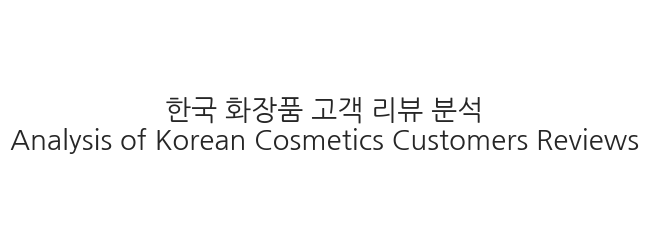

In [28]:
plt.figure(figsize=(8, 3))

# Combined the strings into a single text parameter separated by a newline
plt.text(0.5, 0.5, "한국 화장품 고객 리뷰 분석\nAnalysis of Korean Cosmetics Customers Reviews",
         fontsize=20, ha="center", va="center")

plt.axis("off")
plt.show()

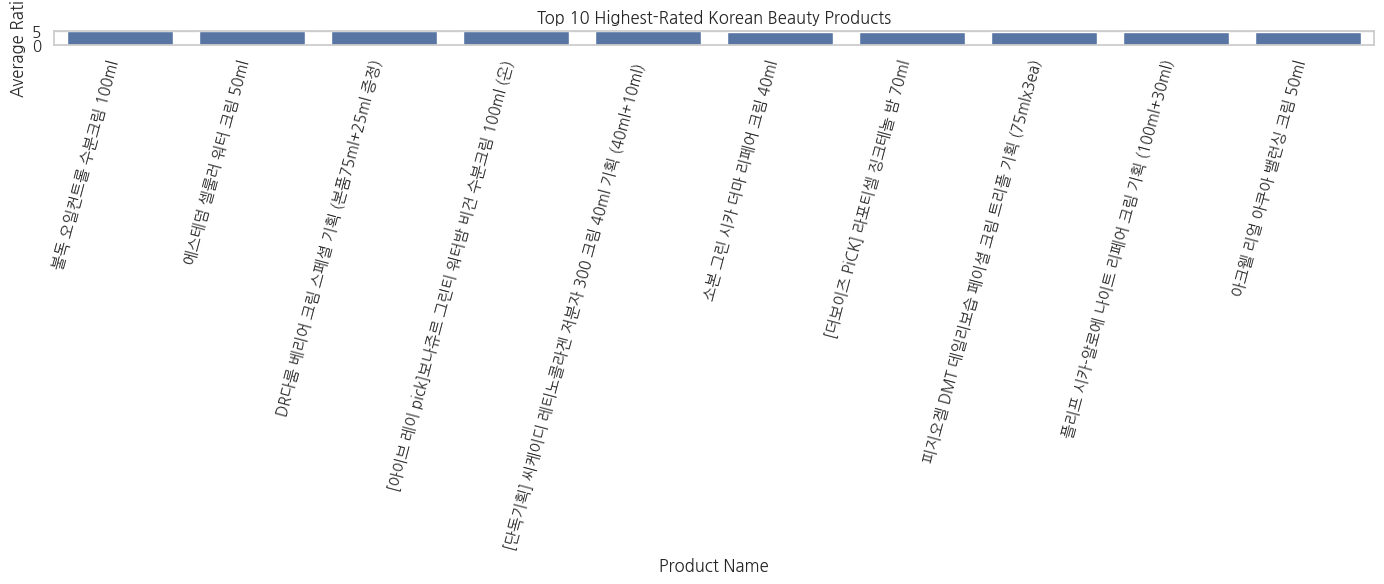

In [29]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=top_rated_products,
    x="product_name",
    y="average_rating"
)

plt.title("Top 10 Highest-Rated Korean Beauty Products")
plt.xlabel("Product Name")
plt.ylabel("Average Rating")

plt.ylim(0, 5)
plt.xticks(rotation=75, ha="right")

plt.tight_layout()
plt.show()

## 1.3 Most Reviewed Products

To identify the 10 Korean beauty products that received the highest number of customer reviews.

This analysis helps us understand which products have the highest customer engagement.


In [30]:
most_reviewed_bilingual = (
    product_ratings_bilingual
    .sort_values(
        by="total_reviews",
        ascending=False
    )
    .head(10)
    .copy()
)

display(
    most_reviewed_bilingual[
        [
            "product_name",
            "product_name_english",
            "total_reviews",
            "average_rating"
        ]
    ]
)

,product_name,product_name_english,total_reviews,average_rating
19,[단독기획] 구달 청귤 비타C 잡티 톤업 크림 (본품50ml+5ml+세럼 5ml 증정),[Exclusive Offer] Goodal Green Tangerine Vita ...,1067,4.51
28,[단독기획] 씨케이디 레티노콜라겐 저분자 300 크림 40ml 기획 (40ml+10...,[Exclusive Offer] CKD Retinocollagen Low Molec...,990,4.96
262,에스트라 아토베리어365 크림 80ml 짝꿍기획 (+하이드로에센스 40ml 증정),Estraderm Atobarrier 365 Cream 80ml Bundle Dea...,990,4.80
45,[문가영 Pick] 더마펌 울트라 수딩 하이드라 크림 R4 50ml (수분진정),[Moon Ga-young's Pick] Dermapum Ultra Soothing...,990,4.76
24,[단독기획] 라운드랩 자작나무 수분크림 더블기획 (80ml+80ml),[Exclusive Offer] Round Lab Birch Juice Moistu...,990,4.63
103,닥터자르트 세라마이딘 울트라 모이스처 크림 50ml,Dr. Jart+ Ceramidin Ultra Moisture Cream 50ml,990,4.74
17,[단독기획] 구달 맑은 어성초 진정 수분크림 (본품75ml+50ml+화장솜 10매 증정),[Exclusive Offer] Goodal Clear Centella Asiati...,990,4.69
104,닥터자르트 세라마이딘 크림 50ml (리퀴드 31ml 증정),Dr. Jart+ Ceramidin Cream 50ml (Liquid 31ml Fr...,990,4.75
146,리얼베리어 익스트림 크림 2+1기획 (50ml+50ml+폼50ml),Real Barrier Extreme Cream 2+1 Special Offer (...,990,4.80
113,더랩바이블랑두 올리고 히알루론산 카밍 + 크림 (본품80ml+20ml 추가 증정),The Lab by Blanc Doux Oligo Hyaluronic Acid Ca...,990,4.69


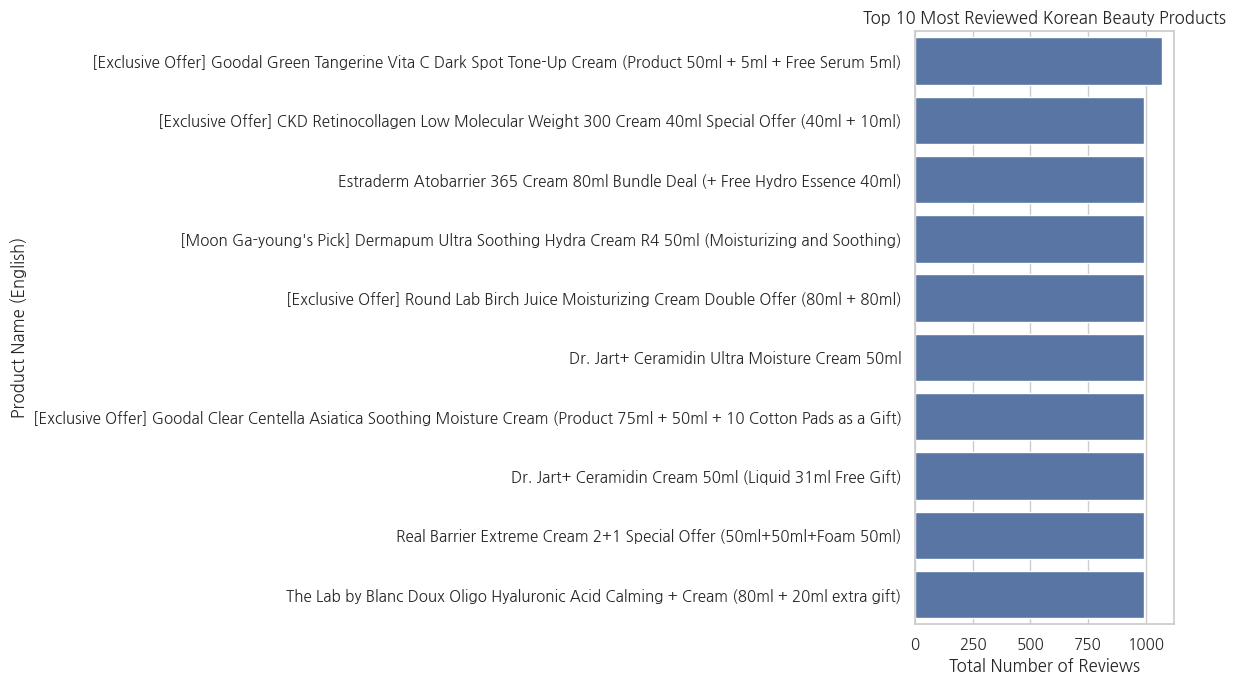

In [31]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=most_reviewed_bilingual,
    x="total_reviews",
    y="product_name_english"
)

plt.title(
    "Top 10 Most Reviewed Korean Beauty Products"
)

plt.xlabel("Total Number of Reviews")
plt.ylabel("Product Name (English)")

plt.tight_layout()
plt.show()

## 1.4 Lowest-Rated Products

To identify the 10 lowest-rated Korean beauty products based on average customer ratings.

Only products with at least 20 reviews are considered to ensure reliable results.

This analysis helps identify products that may require quality improvement.


In [32]:
lowest_rated_bilingual = (
    product_ratings_bilingual[
        product_ratings_bilingual["total_reviews"] >= 20
    ]
    .sort_values(
        by="average_rating",
        ascending=True
    )
    .head(10)
    .copy()
)

display(
    lowest_rated_bilingual[
        [
            "product_name",
            "product_name_english",
            "average_rating",
            "total_reviews"
        ]
    ]
)

,product_name,product_name_english,average_rating,total_reviews
218,셀비엔 구급크림 300ml,Selvien First Aid Cream 300ml,4.30,43
172,바이오더마 시카비오 데이 리페어 크림 30ml 기획,Bioderma Cicabio Day Repair Cream 30ml Special...,4.36,277
278,오리진스 진징 울트라 에너지 부스팅 크림 50ml,Origins Ginzing Ultra Energy Boosting Cream 50ml,4.41,22
86,가히 키스틴밤,Gahi Chestnut,4.41,75
96,눅스 에너지 부스트 나이트 리커버리밤 50ml,Nuxe Energy Boost Night Recovery Balm 50ml,4.42,33
85,가히 엑스틴C밤,Gahi Xteen C Night Cream,4.45,987
141,라운드어라운드 그린티 약산성 마일드 수분크림 80ml,Round Around Green Tea Slightly Acidic Mild Mo...,4.47,91
7,[NEW] 바이오더마 아토덤 인텐시브 젤 크림 200ml,[NEW] Bioderma Atoderm Intensive Gel-Cream 200ml,4.47,230
64,[증정] 아워비건 어성초 시카 크림 (본품100ml+10mlx2 추가 증정),[Gift] Our Vegan Houttuynia Cordata Cica Cream...,4.48,44
31,[단독기획] 앰플엔 펩타이드샷 앰플 투엑스 30ml + 10ml,[Exclusive Offer] Ampoule N Peptide Shot Ampou...,4.50,38


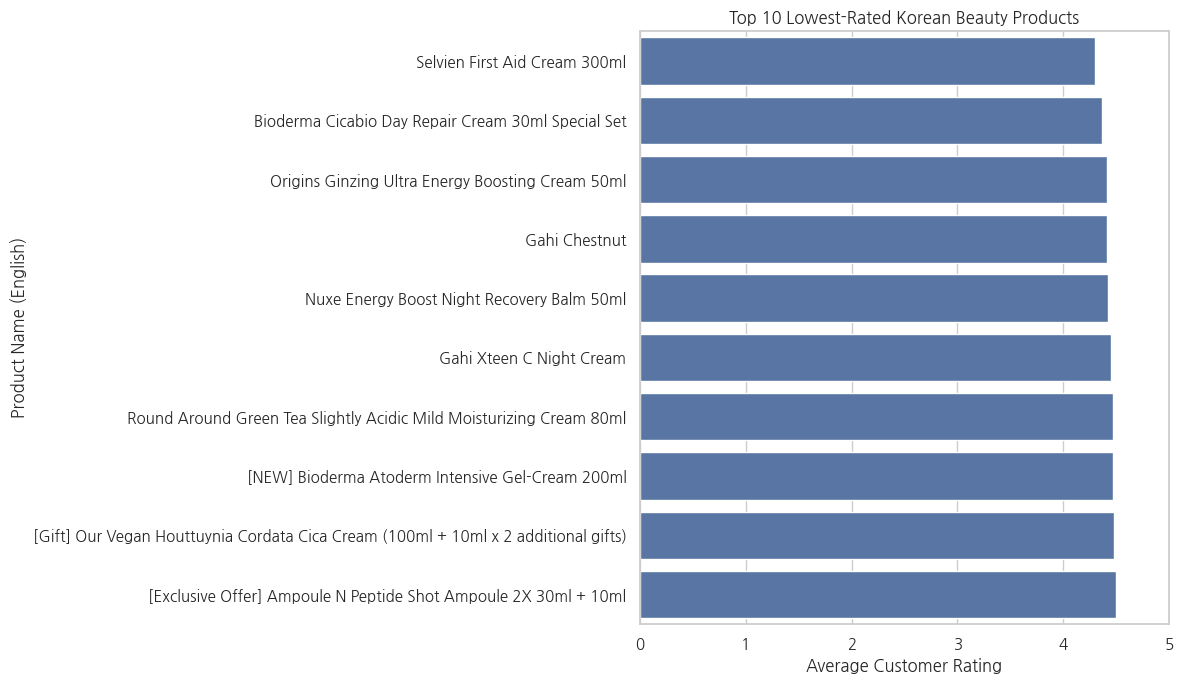

In [33]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=lowest_rated_bilingual,
    x="average_rating",
    y="product_name_english"
)

plt.title(
    "Top 10 Lowest-Rated Korean Beauty Products"
)

plt.xlabel("Average Customer Rating")
plt.ylabel("Product Name (English)")

plt.xlim(0, 5)

plt.tight_layout()
plt.show()

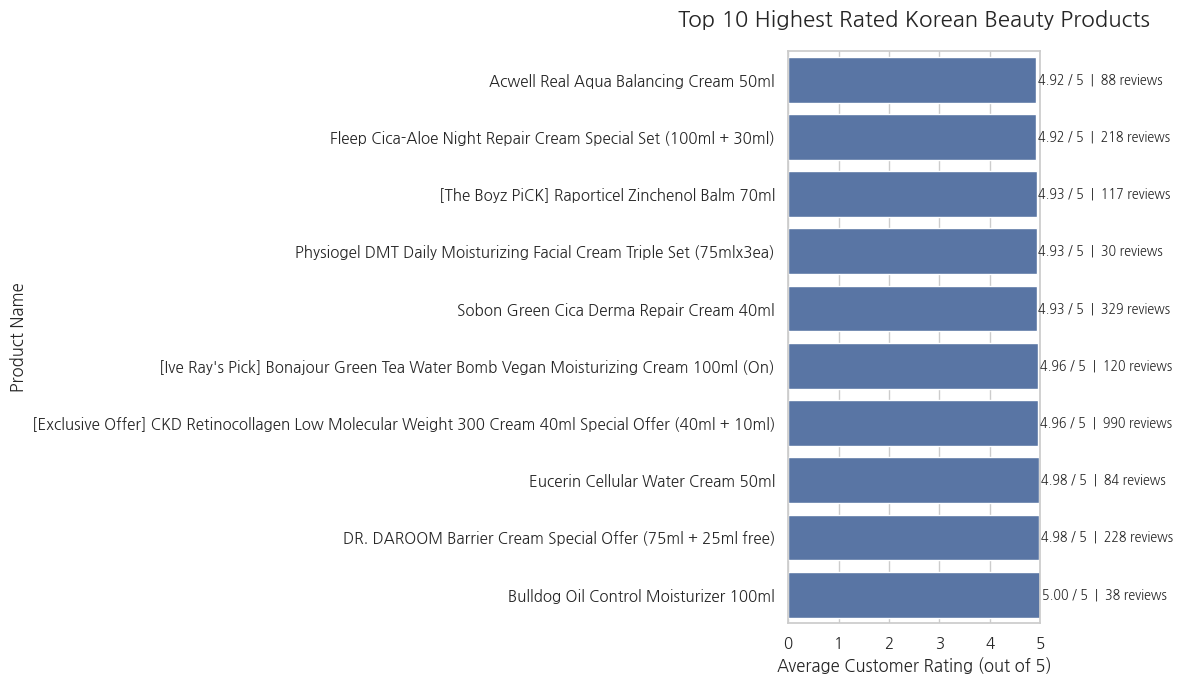

In [34]:

# Top 10 Highest Rated Products
# Minimum 20 reviews for reliable comparison

import matplotlib.pyplot as plt
import seaborn as sns

rating_graph_data = (
    product_ratings_bilingual[
        product_ratings_bilingual["total_reviews"] >= 20
    ]
    .sort_values("average_rating", ascending=False)
    .head(10)
    .sort_values("average_rating", ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=rating_graph_data,
    x="average_rating",
    y="product_name_english"
)

plt.title(
    "Top 10 Highest Rated Korean Beauty Products",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Average Customer Rating (out of 5)", fontsize=12)
plt.ylabel("Product Name", fontsize=12)

plt.xlim(0, 5)

# Display rating and review count beside each bar
for i, row in enumerate(rating_graph_data.itertuples()):
    ax.text(
        row.average_rating + 0.03,
        i,
        f"{row.average_rating:.2f} / 5  |  {row.total_reviews} reviews",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(
    "product_rating_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# PART 2: SKIN TYPE ANALYSIS

## 2.1 Objective

To analyze customer reviews and ratings based on different skin types.

## Business Questions

1. Which skin type has the highest number of customer reviews?
2. Which skin type gives the highest average product rating?
3. How do customer ratings differ across skin types?

In [36]:
print("Available Skin Types:")
print(df["skin_type"].unique())

print("\nTotal Unique Skin Types:")
print(df["skin_type"].nunique())

Available Skin Types:
['복합성' '지성' '건성' '민감성' '트러블성' '약건성' 'Unknown' '웜톤' '각질' '쿨톤' '블랙헤드' '중성'
 '아토피' '모공' '미백' '겨울쿨톤' '여름쿨톤' '트러블' '봄웜톤' '가을웜톤' '주름' '다크서클' '잡티']

Total Unique Skin Types:
23


In [37]:
skin_type_translation = {
    "Unknown": "Unknown",

    "복합성": "Combination Skin",
    "건성": "Dry Skin",
    "약건성": "Slightly Dry Skin",
    "지성": "Oily Skin",
    "민감성": "Sensitive Skin",
    "중성": "Normal Skin",
    "트러블성": "Acne-Prone Skin",

    "모공": "Enlarged Pores",
    "각질": "Dead Skin Cells",
    "미백": "Skin Brightening",
    "블랙헤드": "Blackheads",
    "트러블": "Skin Blemishes",
    "다크서클": "Dark Circles",
    "아토피": "Atopic Skin",
    "잡티": "Dark Spots",
    "주름": "Wrinkles",

    "웜톤": "Warm Undertone",
    "쿨톤": "Cool Undertone",
    "여름쿨톤": "Summer Cool Undertone",
    "겨울쿨톤": "Winter Cool Undertone",
    "가을웜톤": "Autumn Warm Undertone",
    "봄웜톤": "Spring Warm Undertone"
}

df["skin_type_english"] = df["skin_type"].map(
    skin_type_translation
).fillna("Translation Required")

print("Bilingual Skin Type Mapping Completed!")

Bilingual Skin Type Mapping Completed!


In [38]:
untranslated_types = (
    df.loc[
        df["skin_type_english"] == "Translation Required",
        "skin_type"
    ]
    .value_counts()
)

print("Skin Types Still Requiring Translation:")
display(untranslated_types)

Skin Types Still Requiring Translation:


,count
skin_type,


In [39]:
skin_type_counts = (
    df.groupby(
        ["skin_type", "skin_type_english"]
    )
    .size()
    .reset_index(name="total_reviews")
    .sort_values(
        by="total_reviews",
        ascending=False
    )
)

display(skin_type_counts)

,skin_type,skin_type_english,total_reviews
0,Unknown,Unknown,68116
9,복합성,Combination Skin,12131
3,건성,Dry Skin,7052
19,지성,Oily Skin,3245
8,민감성,Sensitive Skin,1052
22,트러블성,Acne-Prone Skin,397
18,중성,Normal Skin,141
15,웜톤,Warm Undertone,118
20,쿨톤,Cool Undertone,106
13,약건성,Slightly Dry Skin,100


In [40]:
print("Untranslated Categories:")

display(
    df.loc[
        df["skin_type_english"] == "Translation Required",
        "skin_type"
    ].value_counts()
)

Untranslated Categories:


,count
skin_type,


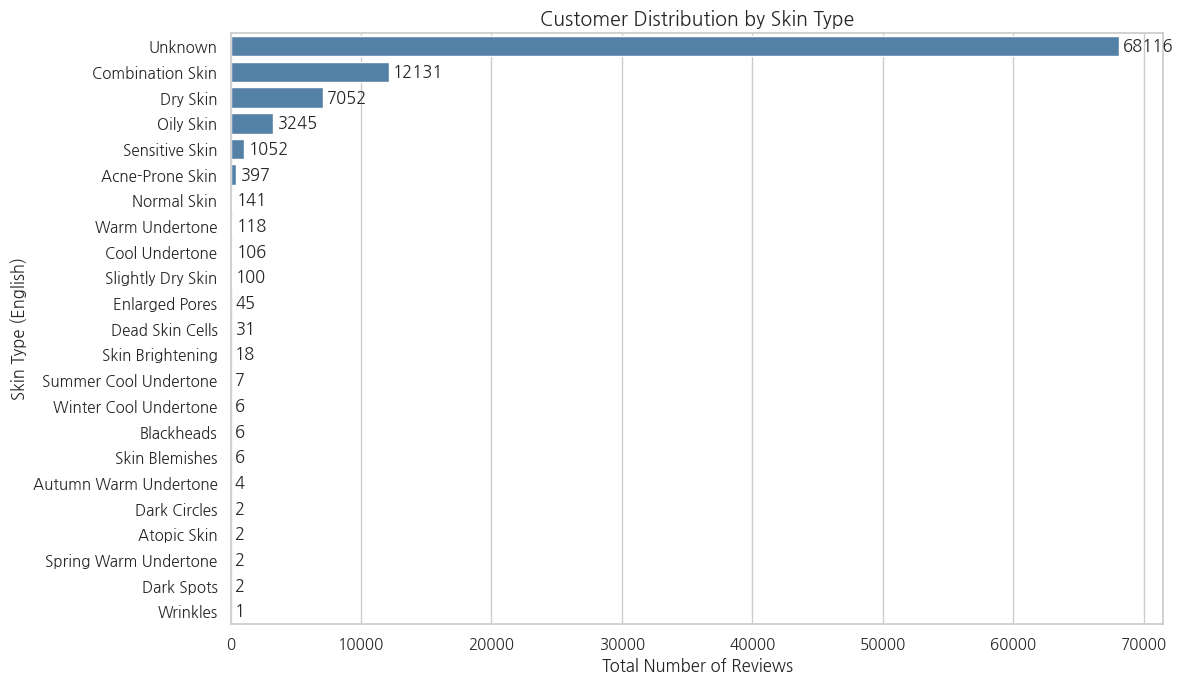

In [41]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=skin_type_counts,
    x="total_reviews",
    y="skin_type_english",
    color="steelblue"
)

plt.title(
    "Customer Distribution by Skin Type",
    fontsize=14
)

plt.xlabel("Total Number of Reviews")
plt.ylabel("Skin Type (English)")

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt="%.0f")

plt.tight_layout()
plt.show()

## 2.2 Skin Type Distribution (Excluding Unknown)

### Objective
To compare the distribution of customer skin types and skin-related categories, excluding unknown entries.

### Business Purpose
To understand which skin categories are most commonly represented among customers who provided this information.

In [42]:
skin_type_known = (
    skin_type_counts[
        skin_type_counts["skin_type"] != "Unknown"
    ]
    .sort_values(
        by="total_reviews",
        ascending=False
    )
    .copy()
)

display(skin_type_known)

,skin_type,skin_type_english,total_reviews
9,복합성,Combination Skin,12131
3,건성,Dry Skin,7052
19,지성,Oily Skin,3245
8,민감성,Sensitive Skin,1052
22,트러블성,Acne-Prone Skin,397
18,중성,Normal Skin,141
15,웜톤,Warm Undertone,118
20,쿨톤,Cool Undertone,106
13,약건성,Slightly Dry Skin,100
6,모공,Enlarged Pores,45


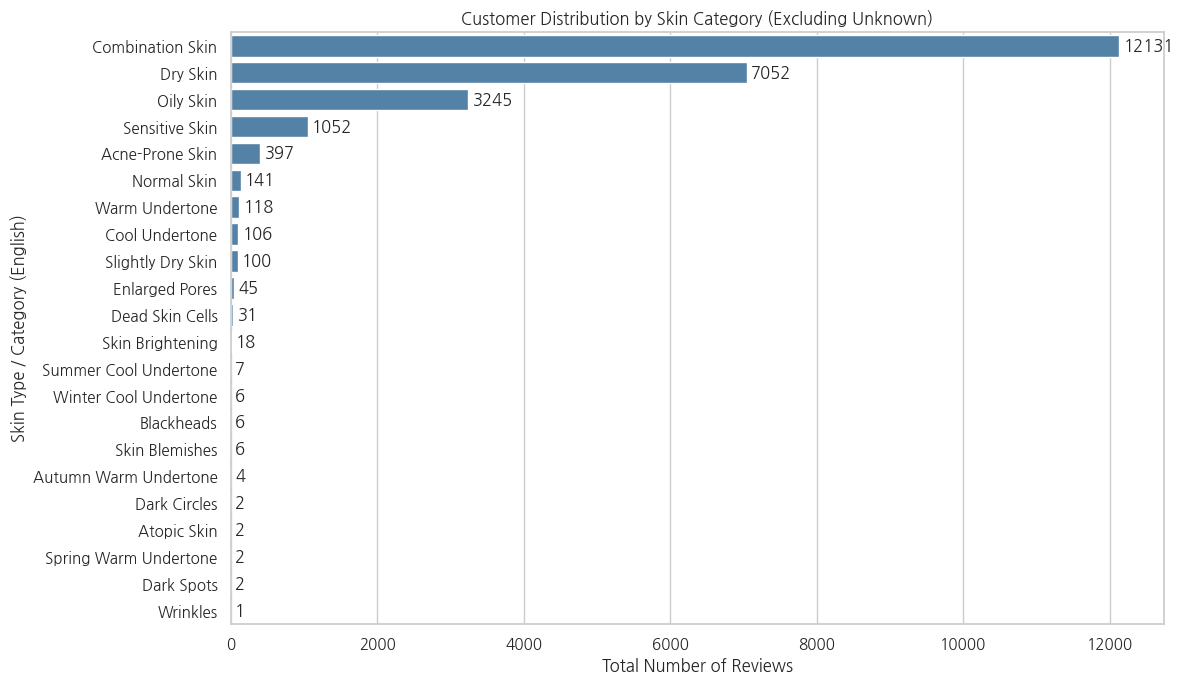

In [43]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=skin_type_known,
    x="total_reviews",
    y="skin_type_english",
    color="steelblue"
)

plt.title(
    "Customer Distribution by Skin Category (Excluding Unknown)"
)

plt.xlabel("Total Number of Reviews")
plt.ylabel("Skin Type / Category (English)")

for container in ax.containers:
    ax.bar_label(container, padding=3, fmt="%.0f")

plt.tight_layout()
plt.show()

## 2.3 Average Customer Rating by Skin Category

### Objective
To compare average product ratings across different skin categories.

### Business Questions
1. Which skin category has the highest average rating?
2. Which skin category has the lowest average rating?
3. How do average ratings differ across categories?

In [44]:
skin_type_ratings = (
    df[df["skin_type"] != "Unknown"]
    .groupby(
        ["skin_type", "skin_type_english"]
    )
    .agg(
        average_rating=("rating", "mean"),
        total_reviews=("rating", "count")
    )
    .reset_index()
)

skin_type_ratings["average_rating"] = (
    skin_type_ratings["average_rating"].round(2)
)

skin_type_ratings = skin_type_ratings.sort_values(
    by="average_rating",
    ascending=False
)

display(skin_type_ratings)

,skin_type,skin_type_english,average_rating,total_reviews
4,다크서클,Dark Circles,5.00,2
11,아토피,Atopic Skin,5.00,2
15,잡티,Dark Spots,5.00,2
20,트러블,Skin Blemishes,5.00,6
10,블랙헤드,Blackheads,5.00,6
6,미백,Skin Brightening,4.89,18
17,중성,Normal Skin,4.84,141
2,건성,Dry Skin,4.76,7052
1,각질,Dead Skin Cells,4.74,31
8,복합성,Combination Skin,4.73,12131


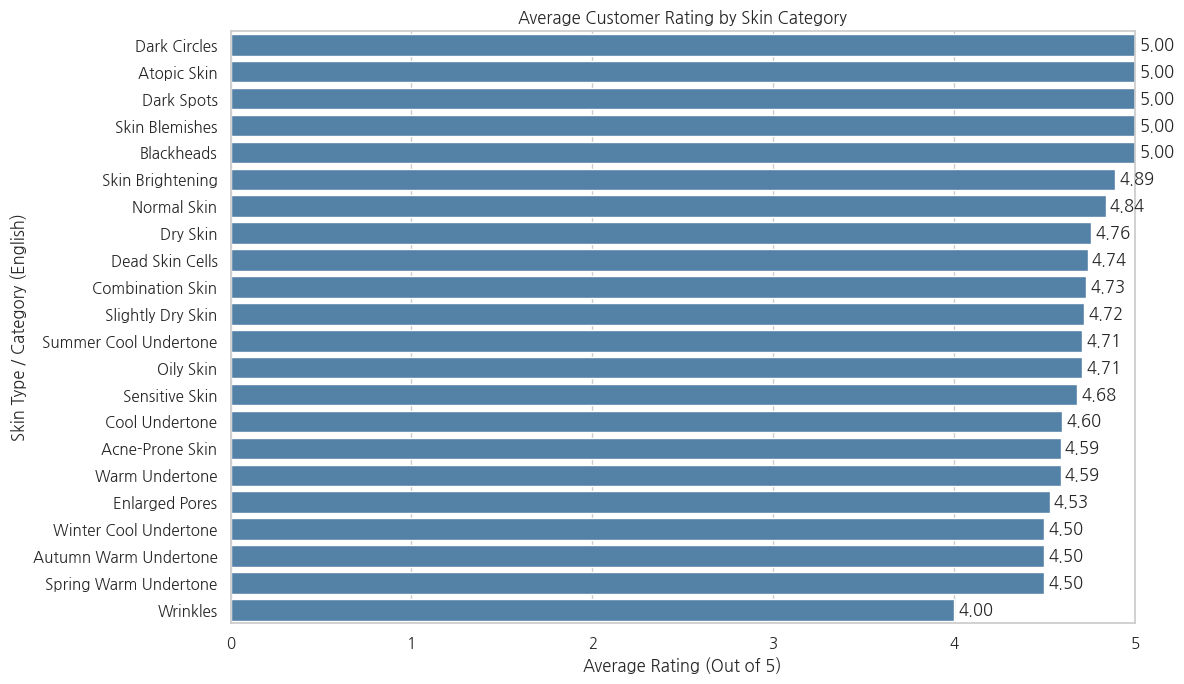

In [45]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=skin_type_ratings,
    x="average_rating",
    y="skin_type_english",
    color="steelblue"
)

plt.title("Average Customer Rating by Skin Category")
plt.xlabel("Average Rating (Out of 5)")
plt.ylabel("Skin Type / Category (English)")

plt.xlim(0, 5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

## 2.4 Reliable Average Rating Comparison

### Objective
To compare average customer ratings across skin categories with at least 20 reviews.

### Business Purpose
To identify customer rating patterns using categories with a reasonable number of reviews.

In [46]:
# Filter categories with at least 20 reviews

skin_type_ratings_reliable = (
    skin_type_ratings[
        skin_type_ratings["total_reviews"] >= 20
    ]
    .sort_values(
        by="average_rating",
        ascending=False
    )
    .copy()
)

display(skin_type_ratings_reliable)

,skin_type,skin_type_english,average_rating,total_reviews
17,중성,Normal Skin,4.84,141
2,건성,Dry Skin,4.76,7052
1,각질,Dead Skin Cells,4.74,31
8,복합성,Combination Skin,4.73,12131
12,약건성,Slightly Dry Skin,4.72,100
18,지성,Oily Skin,4.71,3245
7,민감성,Sensitive Skin,4.68,1052
19,쿨톤,Cool Undertone,4.60,106
21,트러블성,Acne-Prone Skin,4.59,397
14,웜톤,Warm Undertone,4.59,118


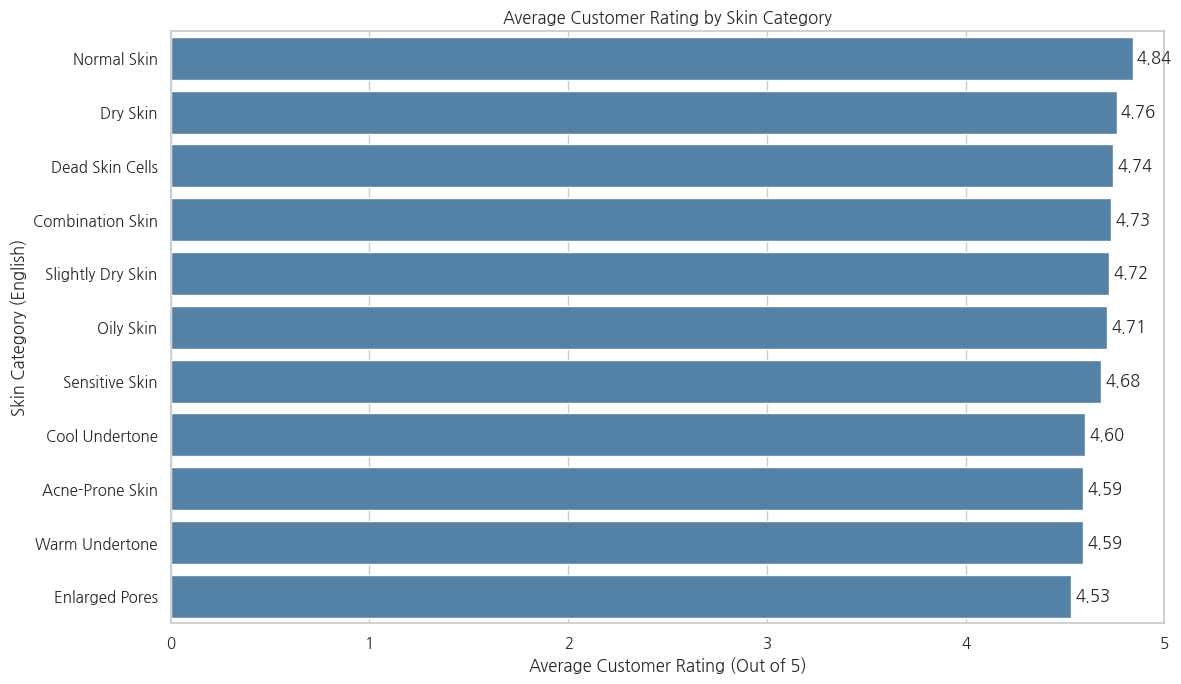

In [47]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=skin_type_ratings_reliable,
    x="average_rating",
    y="skin_type_english",
    color="steelblue"
)

plt.title("Average Customer Rating by Skin Category")
plt.xlabel("Average Customer Rating (Out of 5)")
plt.ylabel("Skin Category (English)")

plt.xlim(0, 5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

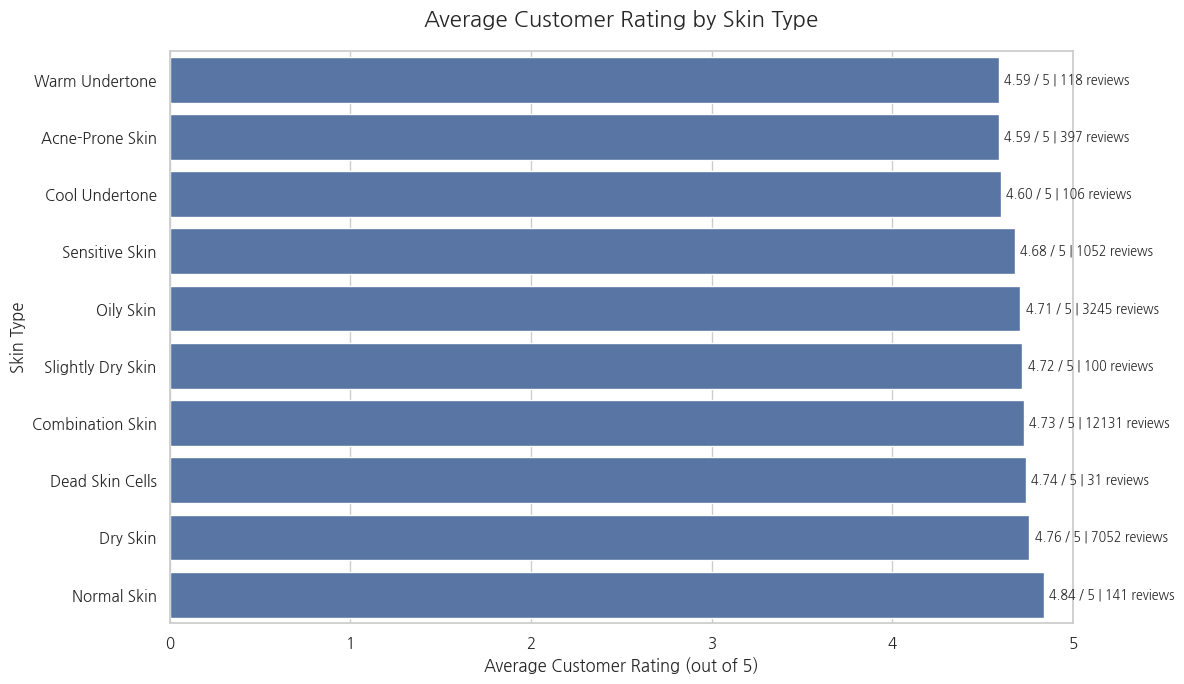

In [48]:

# Professional Skin Type Rating Analysis

skin_graph_data = (
    skin_type_ratings[
        skin_type_ratings["total_reviews"] >= 20
    ]
    .sort_values("average_rating", ascending=False)
    .head(10)
    .sort_values("average_rating", ascending=True)
)

plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=skin_graph_data,
    x="average_rating",
    y="skin_type_english"
)

plt.title(
    "Average Customer Rating by Skin Type",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Average Customer Rating (out of 5)", fontsize=12)
plt.ylabel("Skin Type", fontsize=12)

plt.xlim(0, 5)

for i, row in enumerate(skin_graph_data.itertuples()):
    ax.text(
        row.average_rating + 0.03,
        i,
        f"{row.average_rating:.2f} / 5 | {row.total_reviews} reviews",
        va="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "skin_type_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.5 Business Insights – Skin Type Analysis

1. Combination Skin has the highest number of known skin-category reviews (12,131), followed by Dry Skin (7,052).

2. Dry Skin customers recorded the highest average rating (4.76) among the major skin categories with sufficient reviews.

3. Sensitive Skin recorded an average rating of 4.68, which is slightly lower than the other major skin categories.

4. A large proportion of customers (68,116 reviews) did not specify their skin type.

5. The findings suggest that customer ratings are relatively similar across the major skin categories.

### Conclusion

Combination Skin and Dry Skin customers represent the largest known skin-category groups in the dataset. Further product-level analysis is required to understand which products perform better for different skin categories.

# PART 3: CUSTOMER SATISFACTION ANALYSIS

## 3.1  Objective

To evaluate overall customer satisfaction based on product ratings and rating-derived sentiment labels.

## Business Questions

1. What is the overall average customer rating?
2. What percentage of customers gave positive, neutral, and negative ratings?
3. What is the overall customer satisfaction distribution?

## 3.2 Overall Customer Rating

In [49]:
overall_rating = df["rating"].mean()

print("Overall Average Customer Rating:", round(overall_rating, 2))
print("Total Customer Reviews:", len(df))

Overall Average Customer Rating: 4.72
Total Customer Reviews: 92590



## 3.3 Sentiment Distribution

In [50]:
sentiment_counts = (
    df["sentiment"]
    .value_counts()
    .reset_index()
)

sentiment_counts.columns = [
    "sentiment",
    "total_reviews"
]

sentiment_counts["percentage"] = (
    sentiment_counts["total_reviews"] / len(df) * 100
).round(2)

display(sentiment_counts)

,sentiment,total_reviews,percentage
0,Positive,87435,94.43
1,Neutral,3848,4.16
2,Negative,1307,1.41


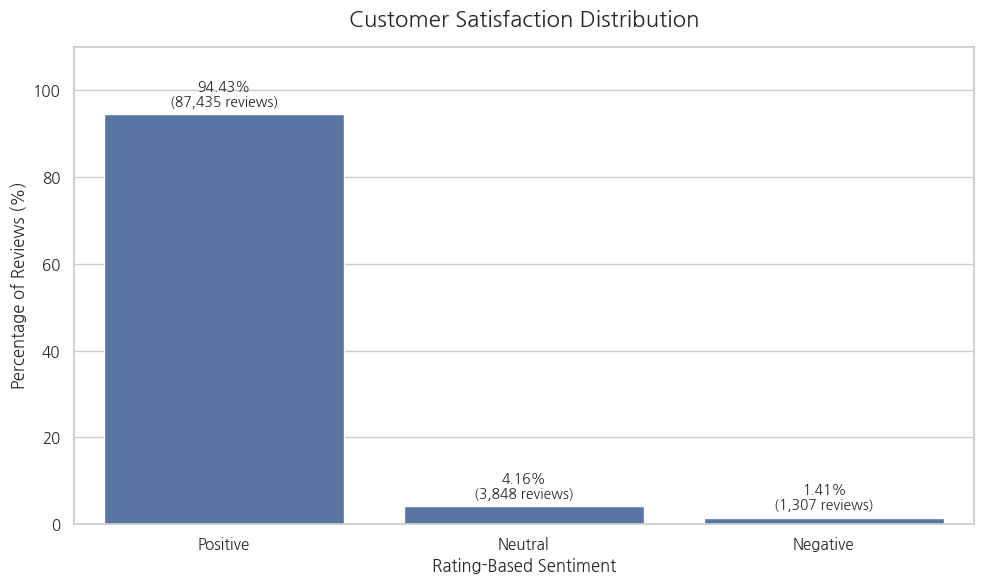

In [53]:

# Customer Satisfaction Distribution

sentiment_counts = df["sentiment"].value_counts()

sentiment_order = ["Positive", "Neutral", "Negative"]

sentiment_data = (
    sentiment_counts
    .reindex(sentiment_order)
    .reset_index()
)

sentiment_data.columns = ["Sentiment", "Total Reviews"]

sentiment_data["Percentage"] = (
    sentiment_data["Total Reviews"] / len(df) * 100
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=sentiment_data,
    x="Sentiment",
    y="Percentage"
)

plt.title(
    "Customer Satisfaction Distribution",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Rating-Based Sentiment", fontsize=12)
plt.ylabel("Percentage of Reviews (%)", fontsize=12)

plt.ylim(0, 110)

for i, row in sentiment_data.iterrows():
    ax.text(
        i,
        row["Percentage"] + 2,
        f'{row["Percentage"]:.2f}%\n({row["Total Reviews"]:,} reviews)',
        ha="center",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    "customer_satisfaction_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [52]:
overall_rating = df["rating"].mean()

print("Overall Average Customer Rating:", round(overall_rating, 2))
print("Total Customer Reviews:", len(df))

Overall Average Customer Rating: 4.72
Total Customer Reviews: 92590



## 3.4 Business Insights – Customer Satisfaction Analysis

1. The dataset contains 92,590 customer reviews with an overall average rating of 4.72 out of 5.
2. Positive reviews account for 94.43% (87,435 reviews), indicating a high level of customer satisfaction based on ratings.
3. Neutral reviews represent 4.16% (3,848 reviews).
4. Negative reviews account for only 1.41% (1,307 reviews).
5. The overall rating distribution suggests that customers generally rated Korean beauty products positively.

### Conclusion
The dataset demonstrates a high level of rating-based customer satisfaction, with an average rating of 4.72 out of 5. However, negative reviews should be examined further to identify product-related issues and opportunities for improvement.

Note: Sentiment categories in this section are derived from numerical ratings, not directly from review text.


# PART 4: PRODUCT COMPARISON ANALYSIS

## 4.1 Objective
To compare Korean beauty products based on average customer ratings and total review counts.

## Business Questions
1. Which products have both high ratings and a large number of reviews?
2. Which products perform better based on customer ratings?
3. How do customer ratings and review counts vary across products?

In [55]:
# Create product-wise comparison dataset

product_comparison = (
    df.groupby(["product_name", "product_name_english"])
    .agg(
        average_rating=("rating", "mean"),
        total_reviews=("rating", "count")
    )
    .reset_index()
)

# Round average ratings
product_comparison["average_rating"] = (
    product_comparison["average_rating"].round(2)
)

# Sort products by total reviews
product_comparison = product_comparison.sort_values(
    by="total_reviews",
    ascending=False
)

print("Total Products:", len(product_comparison))
print("Total Reviews:", product_comparison["total_reviews"].sum())

display(product_comparison.head(10))

Total Products: 351
Total Reviews: 92590


,product_name,product_name_english,average_rating,total_reviews
19,[단독기획] 구달 청귤 비타C 잡티 톤업 크림 (본품50ml+5ml+세럼 5ml 증정),[Exclusive Offer] Goodal Green Tangerine Vita ...,4.51,1067
28,[단독기획] 씨케이디 레티노콜라겐 저분자 300 크림 40ml 기획 (40ml+10...,[Exclusive Offer] CKD Retinocollagen Low Molec...,4.96,990
262,에스트라 아토베리어365 크림 80ml 짝꿍기획 (+하이드로에센스 40ml 증정),Estraderm Atobarrier 365 Cream 80ml Bundle Dea...,4.80,990
45,[문가영 Pick] 더마펌 울트라 수딩 하이드라 크림 R4 50ml (수분진정),[Moon Ga-young's Pick] Dermapum Ultra Soothing...,4.76,990
24,[단독기획] 라운드랩 자작나무 수분크림 더블기획 (80ml+80ml),[Exclusive Offer] Round Lab Birch Juice Moistu...,4.63,990
103,닥터자르트 세라마이딘 울트라 모이스처 크림 50ml,Dr. Jart+ Ceramidin Ultra Moisture Cream 50ml,4.74,990
17,[단독기획] 구달 맑은 어성초 진정 수분크림 (본품75ml+50ml+화장솜 10매 증정),[Exclusive Offer] Goodal Clear Centella Asiati...,4.69,990
104,닥터자르트 세라마이딘 크림 50ml (리퀴드 31ml 증정),Dr. Jart+ Ceramidin Cream 50ml (Liquid 31ml Fr...,4.75,990
146,리얼베리어 익스트림 크림 2+1기획 (50ml+50ml+폼50ml),Real Barrier Extreme Cream 2+1 Special Offer (...,4.80,990
113,더랩바이블랑두 올리고 히알루론산 카밍 + 크림 (본품80ml+20ml 추가 증정),The Lab by Blanc Doux Oligo Hyaluronic Acid Ca...,4.69,990


In [56]:
high_performing_products = product_comparison[
    (product_comparison["average_rating"] >= 4.70) &
    (product_comparison["total_reviews"] >= 100)
]

high_performing_products = high_performing_products.sort_values(
    by=["average_rating", "total_reviews"],
    ascending=False
)

print("Total High-Performing Products:", len(high_performing_products))

display(
    high_performing_products[
        [
            "product_name",
            "product_name_english",
            "average_rating",
            "total_reviews"
        ]
    ]
)

Total High-Performing Products: 115


,product_name,product_name_english,average_rating,total_reviews
4,DR다룸 베리어 크림 스페셜 기획 (본품75ml+25ml 증정),DR. DAROOM Barrier Cream Special Offer (75ml +...,4.98,228
28,[단독기획] 씨케이디 레티노콜라겐 저분자 300 크림 40ml 기획 (40ml+10...,[Exclusive Offer] CKD Retinocollagen Low Molec...,4.96,990
50,[아이브 레이 pick]보나쥬르 그린티 워터밤 비건 수분크림 100ml (온),[Ive Ray's Pick] Bonajour Green Tea Water Bomb...,4.96,120
222,소본 그린 시카 더마 리페어 크림 40ml,Sobon Green Cica Derma Repair Cream 40ml,4.93,329
38,[더보이즈 PiCK] 라포티셀 징크테놀 밤 70ml,[The Boyz PiCK] Raporticel Zinchenol Balm 70ml,4.93,117
...,...,...,...,...
175,바이오힐보 비타민 히알루로닉 젤크림 더블기획(70ml x 2),BIOHEAL BOH Vitamin Hyaluronic Gel Cream Doubl...,4.70,714
22,[단독기획] 더랩바이블랑두 그린 플라보노이드 3.0 크림 더블기획 (50ml+50ml),[Exclusive Offer] The Lab by Blanc Doux Green ...,4.70,345
59,[증량] 마녀공장 비피다 속보습 수분크림 (본품 80ml+20mlx2ea 추가 증정),[Increased Volume] Manyo Factory Bifida Deep M...,4.70,328
308,케어존 아큐어 트러블 진정크림 75ml (아크네폼 31ml 증정),Care Zone Acure Trouble Soothing Cream 75ml (A...,4.70,160


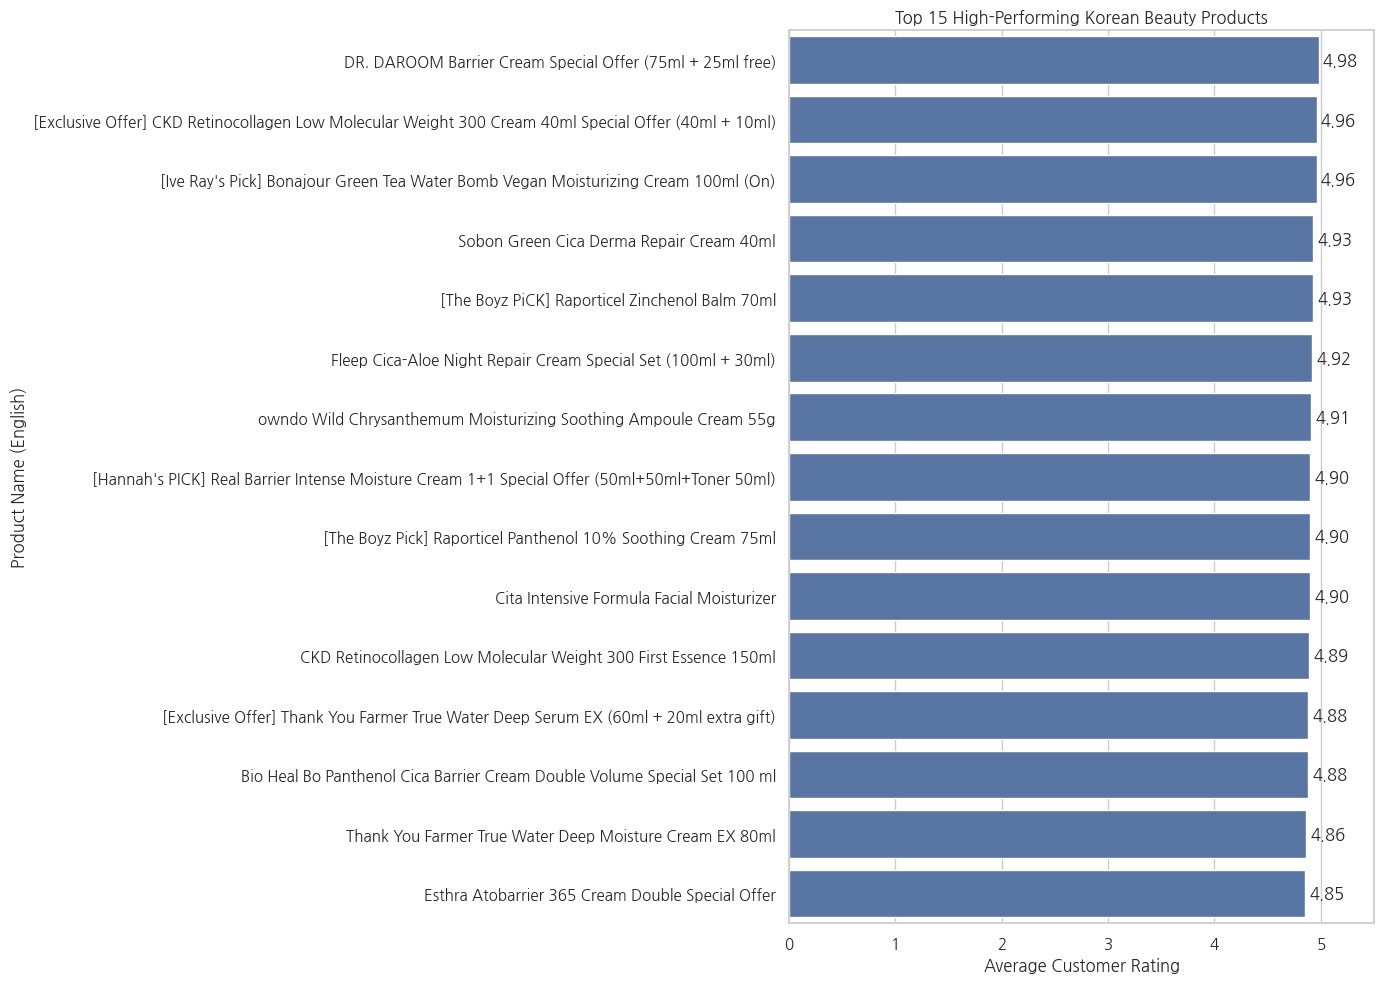

In [57]:
plt.figure(figsize=(14, 10))

top_15_products = high_performing_products.head(15)

ax = sns.barplot(
    data=top_15_products,
    x="average_rating",
    y="product_name_english"
)

plt.title("Top 15 High-Performing Korean Beauty Products")
plt.xlabel("Average Customer Rating")
plt.ylabel("Product Name (English)")
plt.xlim(0, 5.5)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

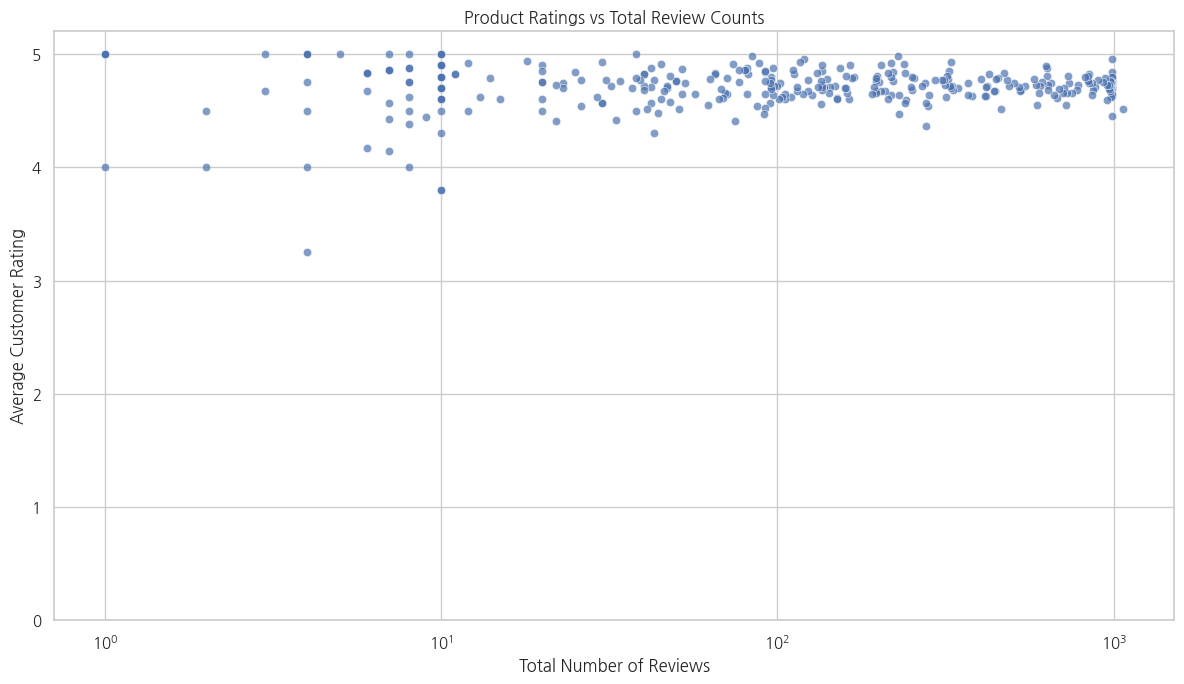

In [58]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=product_comparison,
    x="total_reviews",
    y="average_rating",
    alpha=0.7
)

plt.title("Product Ratings vs Total Review Counts")
plt.xlabel("Total Number of Reviews")
plt.ylabel("Average Customer Rating")

plt.xscale("log")
plt.ylim(0, 5.2)

plt.tight_layout()
plt.show()

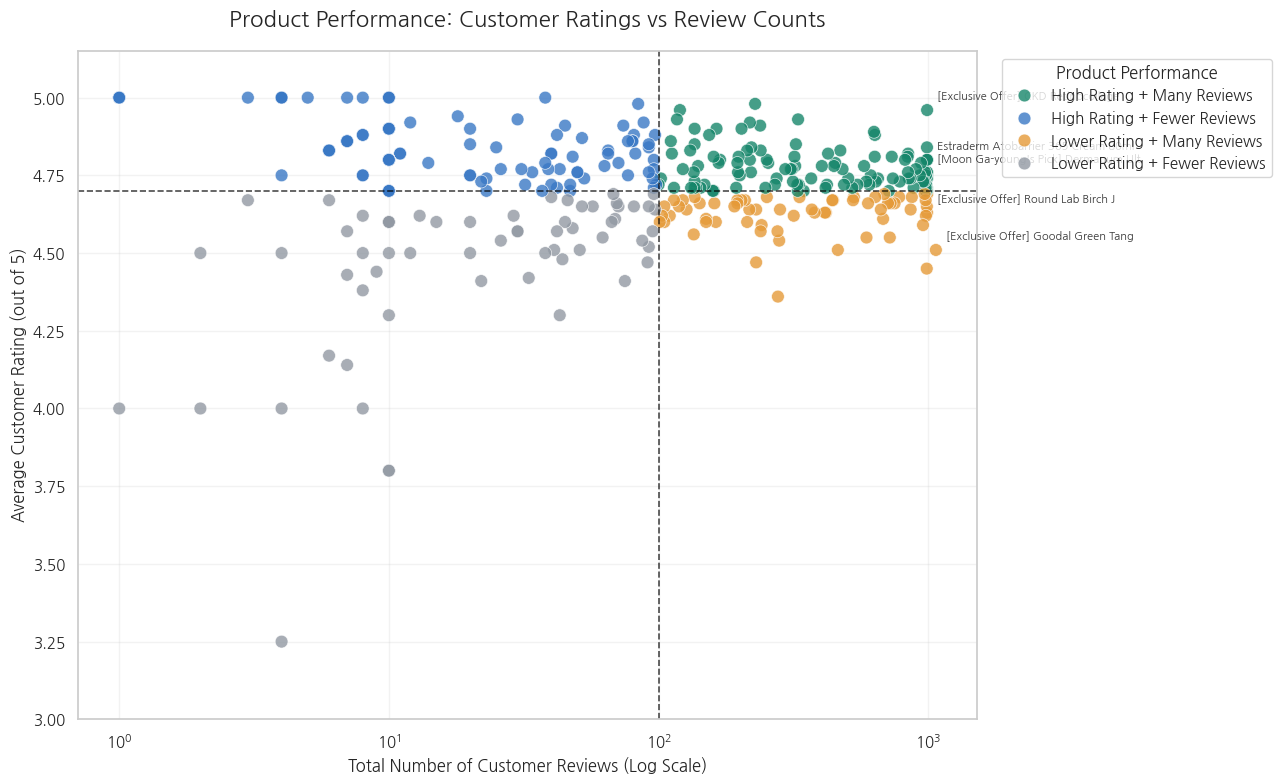

In [59]:

# Professional Product Comparison Scatter Plot

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Copy product comparison data
comparison_graph = product_comparison.copy()

# Create performance categories
conditions = [
    (comparison_graph["average_rating"] >= 4.70) &
    (comparison_graph["total_reviews"] >= 100),

    (comparison_graph["average_rating"] >= 4.70) &
    (comparison_graph["total_reviews"] < 100),

    (comparison_graph["average_rating"] < 4.70) &
    (comparison_graph["total_reviews"] >= 100)
]

categories = [
    "High Rating + Many Reviews",
    "High Rating + Fewer Reviews",
    "Lower Rating + Many Reviews"
]

comparison_graph["Performance"] = np.select(
    conditions,
    categories,
    default="Lower Rating + Fewer Reviews"
)

# Define colors
palette = {
    "High Rating + Many Reviews": "#16866A",
    "High Rating + Fewer Reviews": "#3978C5",
    "Lower Rating + Many Reviews": "#E59A38",
    "Lower Rating + Fewer Reviews": "#9299A3"
}

plt.figure(figsize=(13, 8))

ax = sns.scatterplot(
    data=comparison_graph,
    x="total_reviews",
    y="average_rating",
    hue="Performance",
    hue_order=categories + ["Lower Rating + Fewer Reviews"],
    palette=palette,
    s=85,
    alpha=0.8,
    edgecolor="white",
    linewidth=0.5
)

# Add reference lines
plt.axhline(
    y=4.70,
    color="black",
    linestyle="--",
    linewidth=1.2,
    alpha=0.7
)

plt.axvline(
    x=100,
    color="black",
    linestyle="--",
    linewidth=1.2,
    alpha=0.7
)

# Label top 5 most-reviewed products
top_products = comparison_graph.nlargest(
    5, "total_reviews"
)

for _, row in top_products.iterrows():
    product_label = (
        row["product_name_english"]
        if pd.notna(row["product_name_english"])
        else row["product_name"]
    )

    ax.annotate(
        str(product_label)[:35],
        (row["total_reviews"], row["average_rating"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=8,
        alpha=0.9
    )

plt.title(
    "Product Performance: Customer Ratings vs Review Counts",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Total Number of Customer Reviews (Log Scale)", fontsize=12)
plt.ylabel("Average Customer Rating (out of 5)", fontsize=12)

plt.xscale("log")
plt.ylim(3.0, 5.15)

plt.legend(
    title="Product Performance",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "product_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [60]:
top_10_reviewed = product_comparison.sort_values(
    by="total_reviews",
    ascending=False
).head(10)

display(
    top_10_reviewed[
        [
            "product_name",
            "product_name_english",
            "average_rating",
            "total_reviews"
        ]
    ]
)

,product_name,product_name_english,average_rating,total_reviews
19,[단독기획] 구달 청귤 비타C 잡티 톤업 크림 (본품50ml+5ml+세럼 5ml 증정),[Exclusive Offer] Goodal Green Tangerine Vita ...,4.51,1067
28,[단독기획] 씨케이디 레티노콜라겐 저분자 300 크림 40ml 기획 (40ml+10...,[Exclusive Offer] CKD Retinocollagen Low Molec...,4.96,990
262,에스트라 아토베리어365 크림 80ml 짝꿍기획 (+하이드로에센스 40ml 증정),Estraderm Atobarrier 365 Cream 80ml Bundle Dea...,4.80,990
45,[문가영 Pick] 더마펌 울트라 수딩 하이드라 크림 R4 50ml (수분진정),[Moon Ga-young's Pick] Dermapum Ultra Soothing...,4.76,990
24,[단독기획] 라운드랩 자작나무 수분크림 더블기획 (80ml+80ml),[Exclusive Offer] Round Lab Birch Juice Moistu...,4.63,990
103,닥터자르트 세라마이딘 울트라 모이스처 크림 50ml,Dr. Jart+ Ceramidin Ultra Moisture Cream 50ml,4.74,990
17,[단독기획] 구달 맑은 어성초 진정 수분크림 (본품75ml+50ml+화장솜 10매 증정),[Exclusive Offer] Goodal Clear Centella Asiati...,4.69,990
104,닥터자르트 세라마이딘 크림 50ml (리퀴드 31ml 증정),Dr. Jart+ Ceramidin Cream 50ml (Liquid 31ml Fr...,4.75,990
146,리얼베리어 익스트림 크림 2+1기획 (50ml+50ml+폼50ml),Real Barrier Extreme Cream 2+1 Special Offer (...,4.80,990
113,더랩바이블랑두 올리고 히알루론산 카밍 + 크림 (본품80ml+20ml 추가 증정),The Lab by Blanc Doux Oligo Hyaluronic Acid Ca...,4.69,990


In [61]:
top_10_rated = product_comparison[
    product_comparison["total_reviews"] >= 100
].sort_values(
    by=["average_rating", "total_reviews"],
    ascending=False
).head(10)

display(
    top_10_rated[
        [
            "product_name",
            "product_name_english",
            "average_rating",
            "total_reviews"
        ]
    ]
)

,product_name,product_name_english,average_rating,total_reviews
4,DR다룸 베리어 크림 스페셜 기획 (본품75ml+25ml 증정),DR. DAROOM Barrier Cream Special Offer (75ml +...,4.98,228
28,[단독기획] 씨케이디 레티노콜라겐 저분자 300 크림 40ml 기획 (40ml+10...,[Exclusive Offer] CKD Retinocollagen Low Molec...,4.96,990
50,[아이브 레이 pick]보나쥬르 그린티 워터밤 비건 수분크림 100ml (온),[Ive Ray's Pick] Bonajour Green Tea Water Bomb...,4.96,120
222,소본 그린 시카 더마 리페어 크림 40ml,Sobon Green Cica Derma Repair Cream 40ml,4.93,329
38,[더보이즈 PiCK] 라포티셀 징크테놀 밤 70ml,[The Boyz PiCK] Raporticel Zinchenol Balm 70ml,4.93,117
323,플리프 시카-알로에 나이트 리페어 크림 기획 (100ml+30ml),Fleep Cica-Aloe Night Repair Cream Special Set...,4.92,218
78,owndo 구절초 수분 진정 앰플크림 55g,owndo Wild Chrysanthemum Moisturizing Soothing...,4.91,238
68,[한나네PICK] 리얼베리어 인텐스 모이스처 크림 1+1 기획(50ml+50ml+토...,[Hannah's PICK] Real Barrier Intense Moisture ...,4.90,203
39,[더보이즈 Pick] 라포티셀 판테놀 10% 수딩 크림 75ml,[The Boyz Pick] Raporticel Panthenol 10% Sooth...,4.90,164
230,시타 인텐시브 포뮬러 페이셜 수분크림,Cita Intensive Formula Facial Moisturizer,4.90,136


## 4.3 Business Insights – Product Comparison Analysis

1. The dataset contains 351 unique Korean beauty products with a total of 92,590 customer reviews.

2. A total of 115 products achieved an average rating of 4.70 or above, with at least 100 customer reviews.

3. DR. DAROOM Barrier Cream Special Offer recorded the highest average rating of 4.98 among the identified high-performing products.

4. CKD Retinocollagen Low Molecular 300 Cream achieved an average rating of 4.96 with 990 reviews, indicating strong customer feedback supported by a large review count.

5. Goodal Green Tangerine Vita C Cream received the highest number of reviews (1,067) among the products shown in the initial comparison table, with an average rating of 4.51.

6. The comparison highlights that a high average rating and a high review count represent two different aspects of product performance.

### Conclusion

The product comparison analysis identified 115 high-performing products based on the selected rating and review-count criteria. Some products achieved exceptionally high ratings, while others attracted a larger volume of customer reviews.

These findings can help identify popular and highly rated Korean beauty products and support further investigation into customer preferences and product performance.

Note: The thresholds of 4.70 average rating and 100 reviews are selected for this analysis and are not universal industry standards.

# PART 5: KOREAN REVIEW TRANSLATION

## 5.1 Objective

To translate Korean customer reviews into English while preserving the original Korean review text. This will make customer feedback easier to understand and support further text-based sentiment and keyword analysis.

## Business Questions

1. How many customer reviews are available in Korean?
2. Can Korean customer reviews be translated into English?
3. What percentage of customer reviews are successfully translated?
4. What insights can be obtained from translated customer feedback?

In [62]:
print("Total Reviews:", len(df))

print(
    "Available Reviews:",
    df["review"].notna().sum()
)

print(
    "Missing Reviews:",
    df["review"].isna().sum()
)

display(
    df[["review"]].dropna().head(10)
)

Total Reviews: 92590
Available Reviews: 92590
Missing Reviews: 0


,review
0,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...
1,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨..."
2,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름...
3,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...
4,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔..."
5,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...
6,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...
7,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...
8,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...
9,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...


In [63]:
total_reviews = df["review"].dropna().shape[0]

unique_reviews = df["review"].dropna().nunique()

duplicate_reviews = total_reviews - unique_reviews

print("Total Available Reviews:", total_reviews)
print("Unique Reviews:", unique_reviews)
print("Duplicate Reviews:", duplicate_reviews)

Total Available Reviews: 92590
Unique Reviews: 92590
Duplicate Reviews: 0


In [64]:
def translate_long_review(review):

    try:
        if len(review) <= 400:
            return translator_alt.translate(review)

        translated_chunks = []

        for i in range(0, len(review), 400):

            chunk = review[i:i+400]

            translated_chunk = translator_alt.translate(chunk)

            translated_chunks.append(translated_chunk)

            time.sleep(1)

        return " ".join(translated_chunks)

    except Exception as e:

        print("Translation Error:", str(e))

        return None

In [65]:
sample_reviews = (
    df["review"]
    .dropna()
    .astype(str)
    .str.strip()
)

sample_reviews = sample_reviews[
    sample_reviews != ""
].unique()[:5]

for i, review in enumerate(sample_reviews):

    english_review = translate_long_review(review)

    print(f"\nReview {i+1}")
    print("Korean:", review[:300])
    print("English:", english_review)

    print("-" * 80)


Review 1
Korean: Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여드름 고민없었고,흔하디흔한 뽀루지도 한해에 한번 날까하는 그런 피부였어요그런데 올초에 새로산 마스크로인해 갑자기 피부염이 생겨 한달넘게 정말 고생을 많이 했어요피부과 처방과 추천제품,약사 추천,좋다는 화장품은 죄다 구매해서 사용해보았으나 정말 효과없어 거울볼때마다 많이 울었어요ㅠㅠ진짜 올리브영에서 판매하는 베스트순위에 있는 크림제품류는 거의 다 구매한것 같아요평소에는 아무렇지도않던 기존제품들도 사용시 따갑고 가렵고 자극만 될뿐 도움이 되지않았는데예전에
English: I highly recommend trying Dr.G products. They are really good products. I didn't have acne problems during puberty, and I had the kind of skin that would get a common pimple maybe once a year. However, earlier this year, I suddenly developed dermatitis due to a new mask I bought, and I really suffered a lot for over a month. I tried all the dermatologist-prescribed and recommended products, pharmacist-recommended products, and supposedly good cosmetics, but they were all ineffective, and I cried a lot every time I looked in the mirror. I cried. :( I think I've bought almost all of the top-ranking cream products sold at Olive Young. Even the existing products that 

In [66]:
review_data = df[
    ["source_id", "product_name", "product_name_english", "review"]
].copy()

print("Total Reviews:", len(review_data))

print("Unique Products:", review_data["product_name"].nunique())

display(review_data.head(5))

Total Reviews: 92590
Unique Products: 351


,source_id,product_name,product_name_english,review
0,1,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...
1,2,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨..."
2,3,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름...
3,4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...
4,5,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),[Increased Quantity] Dr.G Red Blemish Clear So...,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔..."



# PART 6: SENTIMENT ANALYSIS

## 6.1 Objective

To analyze customer opinions and emotions expressed in Korean beauty product reviews using review text rather than rating-based sentiment labels.

## Business Questions

1. What positive and negative expressions are commonly used by customers?
2. What emotions and opinions are reflected in customer reviews?
3. What are the most common positive and negative customer experiences?
4. How can businesses use customer feedback to improve their products?

## 6.2 Analysis Approach

This section will focus on text-based sentiment analysis using the original Korean customer reviews.

Unlike the previous rating-based sentiment analysis, this section will explore the actual words and expressions used by customers.

The original Korean review text will be preserved throughout the analysis.


In [67]:

# Check cleaned review data

print("Total Reviews:", len(df))

print("Missing Cleaned Reviews:",
      df["cleaned_review"].isna().sum())

print("\nSample Korean Reviews:")

display(
    df[["review", "cleaned_review"]].head(10)
)


Total Reviews: 92590
Missing Cleaned Reviews: 0

Sample Korean Reviews:


,review,cleaned_review
0,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...
1,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...","👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨..."
2,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름...,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...
3,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...
4,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...","닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔..."
5,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...
6,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...
7,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...
8,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...
9,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...


In [68]:

# Calculate Korean review length

df["review_length"] = (
    df["cleaned_review"]
    .fillna("")
    .astype(str)
    .str.len()
)

print("Average Review Length:",
      round(df["review_length"].mean(), 2))

print("Maximum Review Length:",
      df["review_length"].max())

print("Minimum Review Length:",
      df["review_length"].min())

display(
    df[["cleaned_review", "review_length"]].head(10)
)


Average Review Length: 198.33
Maximum Review Length: 1349
Minimum Review Length: 9


,cleaned_review,review_length
0,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,959
1,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...",867
2,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...,528
3,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,470
4,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...",455
5,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...,946
6,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...,474
7,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...,455
8,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...,413
9,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...,527


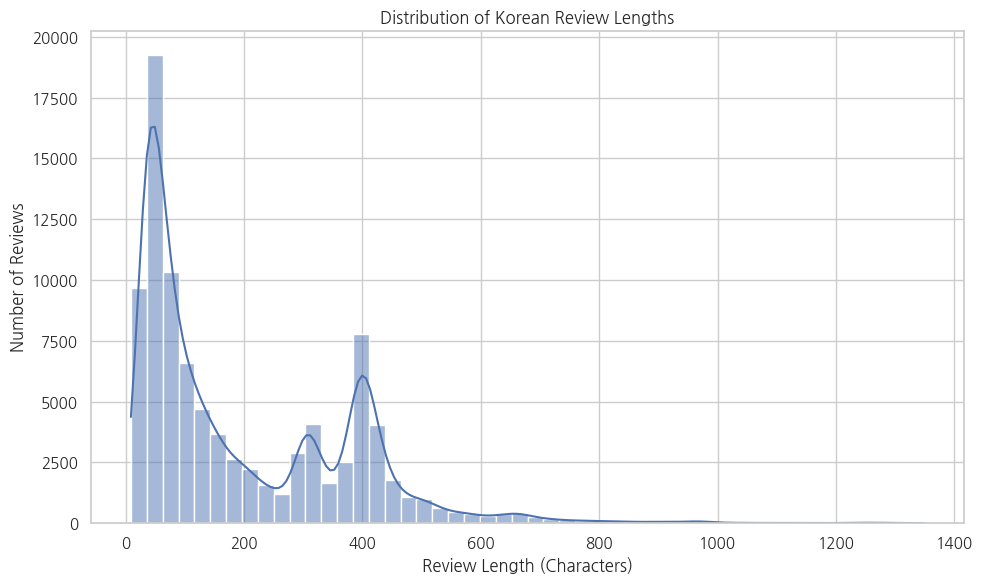

In [69]:

# Review length distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    df["review_length"],
    bins=50,
    kde=True
)

plt.title("Distribution of Korean Review Lengths")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()



## 6.3 Review Length Analysis - Key Findings

The review length analysis of 92,590 Korean customer reviews revealed the following findings:

1. All 92,590 reviews contain available cleaned review text.
2. The average review length is approximately 198 characters.
3. The shortest review contains 9 characters, while the longest contains 1,349 characters.
4. The distribution is right-skewed, indicating that most reviews are relatively short, while a smaller number contain detailed customer experiences.
5. A noticeable concentration of reviews is also observed around the 300–450 character range.

These findings indicate that the dataset contains both short customer feedback and detailed product experiences, providing useful textual information for further sentiment analysis.



## 6.4 Korean Text-Based Sentiment Analysis

A pre-trained Korean sentiment classification model will be evaluated to identify customer opinions directly from Korean review text.

The model classifies reviews into two categories:

- Positive: 긍정
- Negative: 부정

The model will first be tested on a sample of 10 customer reviews to evaluate its output before applying it to the complete dataset.

Note: This model does not provide a Neutral category. Its predictions are model-generated labels and may not always reflect the actual customer opinion.


In [70]:

# Import required libraries

import torch
from transformers import pipeline

# Load Korean sentiment analysis model

model_name = "WhitePeak/bert-base-cased-Korean-sentiment"

sentiment_classifier = pipeline(
    "text-classification",
    model=model_name,
    device=0 if torch.cuda.is_available() else -1
)

print("Korean Sentiment Model Loaded Successfully!")


config.json:   0%|          | 0.00/895 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  711MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/367 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  711MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Korean Sentiment Model Loaded Successfully!


In [71]:

# Select 10 sample Korean reviews

sample_reviews = (
    df["cleaned_review"]
    .dropna()
    .head(10)
    .tolist()
)

# Predict sentiment

sample_predictions = sentiment_classifier(
    sample_reviews,
    truncation=True,
    max_length=512,
    batch_size=5
)

# Display results

for i, (review, prediction) in enumerate(
    zip(sample_reviews, sample_predictions), start=1
):
    label = prediction["label"]

    sentiment_label = {
        "LABEL_0": "Negative",
        "LABEL_1": "Positive"
    }.get(label, label)

    print(f"\nReview {i}")
    print("Korean Review:", review[:200])
    print("Predicted Sentiment:", sentiment_label)
    print("Confidence:", round(prediction["score"], 4))



Review 1
Korean Review: Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여드름 고민없었고,흔하디흔한 뽀루지도 한해에 한번 날까하는 그런 피부였어요그런데 올초에 새로산 마스크로인해 갑자기 피부염이 생겨 한달넘게 정말 고생을 많이 했어요피부과 처방과 추천제품,약사 추천,좋다는 화장품은 죄다 구매해서 사용해보았으나 정말 효과없어 거울볼때마다 많이 울었어
Predicted Sentiment: Negative
Confidence: 0.9784

Review 2
Korean Review: 👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨울엔 두겹 레이어링하면 쫀쫀, 좋은 성분, 가성비와 가심비!- bad! : 단지형용기! 30ml샘플처럼 튜브형에 나오면 더 좋을듯- 꿀팁 : 순해서 다른 화장품과 궁합이 좋은 편! 빠른 진정이 필요할 때 연고처럼 나온 꾸덕한 크림과 섞어서 슬리핑팩처럼 올려주면 다음날 피부상태
Predicted Sentiment: Positive
Confidence: 0.9912

Review 3
Korean Review: ❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 짜거나 엄청 예민해져 있는 시기에 발라도 전혀 따갑지 않고 다음날 아침에 일어나면 80프로는 진정되어 있어요 수분도 짱짱 저같이 병풀이나 히알루론산이 잘 안맞고 글리세린 잘 맞으시는 분들에게는 진짜 인생템일거에요! 수분감 💙단점: 저녁에는 수면팩으로 많이 바르라고 광고하는데 
Predicted Sentiment: Positive
Confidence: 0.6741

Review 4
Korean Review: 또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가서 피부에 남아있는 시간이 적다 이렇게 느끼실 수도 있을거에요. 그렇지만 지성인 저에게는..진짜 참된 제품입니다.지성분들은 아실거에요. 피부에 묵직하게 남아있으면 기름기인것 같고 기분나쁜


## 6.5 Sentiment Model Evaluation

The initial sample test produced both positive and negative sentiment predictions.

However, some customer reviews contain mixed opinions and detailed product experiences. Therefore, the model's input length and prediction confidence will be examined before applying sentiment classification to the complete dataset.


In [72]:

# Check token lengths of sample reviews

token_lengths = []

for review in sample_reviews:
    tokens = sentiment_classifier.tokenizer(
        review,
        truncation=False
    )

    token_lengths.append(
        len(tokens["input_ids"])
    )

token_analysis = pd.DataFrame({
    "Review Number": range(1, 11),
    "Token Length": token_lengths
})

token_analysis["Exceeds 512 Tokens"] = (
    token_analysis["Token Length"] > 512
)

display(token_analysis)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (679 > 512). Running this sequence through the model will result in indexing errors


,Review Number,Token Length,Exceeds 512 Tokens
0,1,679,True
1,2,559,True
2,3,351,False
3,4,329,False
4,5,317,False
5,6,633,True
6,7,328,False
7,8,296,False
8,9,253,False
9,10,354,False


In [73]:

# Check model's maximum input length

print(
    "Model Maximum Input Length:",
    sentiment_classifier.tokenizer.model_max_length
)

print(
    "Reviews exceeding 512 tokens:",
    sum(length > 512 for length in token_lengths)
)


Model Maximum Input Length: 512
Reviews exceeding 512 tokens: 3



## 6.6 Handling Long Customer Reviews

The sentiment model supports a maximum input length of 512 tokens.

During the sample evaluation, 3 out of 10 reviews exceeded this limit.

To reduce information loss, longer reviews will be divided into smaller token-based chunks. Each chunk will be analyzed separately, and the predictions will be combined to obtain an overall sentiment for the review.

This approach will be evaluated on the long sample reviews before processing the complete dataset.


In [74]:

# Function to analyze long Korean reviews

def analyze_long_review(review):

    tokenizer = sentiment_classifier.tokenizer

    # Convert review into tokens
    input_ids = tokenizer(
        review,
        add_special_tokens=False
    )["input_ids"]

    chunk_size = 450
    review_chunks = []

    # Divide review into smaller chunks
    for i in range(0, len(input_ids), chunk_size):

        chunk_ids = input_ids[i:i + chunk_size]

        chunk_text = tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        )

        review_chunks.append(chunk_text)

    # Predict sentiment for each chunk
    predictions = sentiment_classifier(
        review_chunks,
        truncation=True,
        max_length=512,
        batch_size=4
    )

    # Count positive and negative predictions
    positive_count = 0
    negative_count = 0

    for prediction in predictions:

        if prediction["label"] == "LABEL_1":
            positive_count += 1

        else:
            negative_count += 1

    # Determine overall sentiment
    if positive_count > negative_count:
        overall_sentiment = "Positive"

    elif negative_count > positive_count:
        overall_sentiment = "Negative"

    else:
        overall_sentiment = "Tie"

    return {
        "total_chunks": len(review_chunks),
        "positive_chunks": positive_count,
        "negative_chunks": negative_count,
        "overall_sentiment": overall_sentiment
    }


In [75]:

# Test long review sentiment analysis

long_review_indices = [0, 1, 5]

for index in long_review_indices:

    review = sample_reviews[index]

    result = analyze_long_review(review)

    print(f"\nReview {index + 1}")
    print("Total Chunks:", result["total_chunks"])
    print("Positive Chunks:", result["positive_chunks"])
    print("Negative Chunks:", result["negative_chunks"])
    print("Overall Sentiment:", result["overall_sentiment"])



Review 1
Total Chunks: 2
Positive Chunks: 0
Negative Chunks: 2
Overall Sentiment: Negative

Review 2
Total Chunks: 2
Positive Chunks: 1
Negative Chunks: 1
Overall Sentiment: Tie

Review 6
Total Chunks: 2
Positive Chunks: 2
Negative Chunks: 0
Overall Sentiment: Positive



## 6.7 Chunk-Level Sentiment Evaluation

Long customer reviews may contain both positive and negative opinions.

Therefore, individual chunk predictions and their confidence scores will be examined to understand how sentiment varies across different sections of a review.

Reviews with conflicting predictions will be treated as mixed or uncertain rather than forcing them into a single sentiment category.


### 6.7.1 Chunk-Level Evaluation – Key Findings

The chunk-level evaluation of three sample reviews revealed the following:

1. Review 1 received Negative predictions for both chunks, indicating consistent negative sentiment across the review.
2. Review 2 received different predictions: Positive for the first chunk and Negative for the second chunk. This indicates mixed customer feedback.
3. Review 6 received Positive predictions for both chunks, indicating consistent positive sentiment.

**Key Observation:**

Customer reviews may contain multiple opinions and experiences. Therefore, analyzing long reviews in smaller chunks can help identify changes in sentiment within the same review.

However, these results are based on only three sample reviews and do not establish the overall accuracy of the sentiment classification model.

In [76]:
# Examine individual chunk predictions and confidence scores

def inspect_review_chunks(review):

    tokenizer = sentiment_classifier.tokenizer

    input_ids = tokenizer(
        review,
        add_special_tokens=False
    )["input_ids"]

    chunk_size = 450
    review_chunks = []

    for i in range(0, len(input_ids), chunk_size):

        chunk_ids = input_ids[i:i + chunk_size]

        chunk_text = tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        )

        review_chunks.append(chunk_text)

    predictions = sentiment_classifier(
        review_chunks,
        truncation=True,
        max_length=512,
        batch_size=4
    )

    results = []

    for i, prediction in enumerate(predictions, start=1):

        sentiment = {
            "LABEL_0": "Negative",
            "LABEL_1": "Positive"
        }.get(prediction["label"], prediction["label"])

        results.append({
            "Chunk": i,
            "Predicted Sentiment": sentiment,
            "Confidence": round(prediction["score"], 4)
        })

    return pd.DataFrame(results)

In [77]:
# Inspect Review 1, Review 2 and Review 6

for index in [0, 1, 5]:

    print(f"\nReview {index + 1} - Chunk Predictions")

    display(
        inspect_review_chunks(sample_reviews[index])
    )


Review 1 - Chunk Predictions


,Chunk,Predicted Sentiment,Confidence
0,1,Negative,0.9754
1,2,Negative,0.6757



Review 2 - Chunk Predictions


,Chunk,Predicted Sentiment,Confidence
0,1,Positive,0.9922
1,2,Negative,0.9609



Review 6 - Chunk Predictions


,Chunk,Predicted Sentiment,Confidence
0,1,Positive,0.6871
1,2,Positive,0.9771


### 6.8 Sentiment Model Evaluation on a Larger Sample

To further examine the sentiment classification model, a sample of 50 Korean customer reviews will be analyzed.

The sample will help us understand the model's predictions across different reviews and identify possible classification inconsistencies before applying sentiment analysis to the complete dataset.

In [78]:
# Select 50 sample reviews
evaluation_sample = (
    df["cleaned_review"]
    .dropna()
    .sample(n=50, random_state=42)
    .tolist()
)

print("Total Sample Reviews:", len(evaluation_sample))

Total Sample Reviews: 50


In [79]:
# Predict sentiment for 50 sample reviews
evaluation_predictions = sentiment_classifier(
    evaluation_sample,
    truncation=True,
    max_length=512,
    batch_size=8
)

# Convert model labels into readable sentiment
evaluation_results = pd.DataFrame({
    "Review": evaluation_sample,
    "Predicted Sentiment": [
        "Positive" if p["label"] == "LABEL_1" else "Negative"
        for p in evaluation_predictions
    ],
    "Confidence": [
        round(p["score"], 4)
        for p in evaluation_predictions
    ]
})

display(evaluation_results.head(10))

,Review,Predicted Sentiment,Confidence
0,세라마이드가 되게 좋다는 소리를 많이 들어서 이 제품이 할인 하길래 한번 구매해봤어...,Negative,0.8497
1,수분진정 답게 정말 수분에 도움을 주은 제품이라 생각해요 밀리지 않고 좋아요,Positive,0.9904
2,라네즈에서 나온 신상품이라 믿고 써 봤습니다 ᄒᄒ 우선 용기랑 상자에 전부 재생지가...,Positive,0.9922
3,"본인:20대,복합성피부,민감성피부,여드름 자주 올라옴..!!ᅲ🙂기존에 브링그린 티트...",Positive,0.9812
4,라운드랩 제품은 그냥 믿고 씁니다.. 워낙 예민하고 민감한 피부에도 자극없이 순한 ...,Positive,0.9899
5,와 진짜 이거 대박입니다!저는 수부지이고 환절기 및 겨울 되면서 u존이 정말 갈라질...,Positive,0.9922
6,아벤느로 하나씩 다 바꿔가고 있어요마스크쓰고 나서 피부가 더 예민해졌는데ᅲᅲ아벤느 ...,Positive,0.9922
7,크림이라 기름질줄 알았는데바르고나면 끈적임이나 미끄럽고 그러지 않아서너무 좋아요!!...,Positive,0.9920
8,레이저하고나서 피부가 많이 건조하더라구요수분크림 이것저것 발라봤는데도 진정이 안되서...,Positive,0.9922
9,크리니크 수분크림은 유명한 이유가 있는거 같아요.전체적으로 좋은거 같아요,Positive,0.9885


In [80]:
# Count predicted sentiments
sentiment_distribution = (
    evaluation_results["Predicted Sentiment"]
    .value_counts()
    .reset_index()
)

sentiment_distribution.columns = [
    "Predicted Sentiment",
    "Total Reviews"
]

display(sentiment_distribution)

,Predicted Sentiment,Total Reviews
0,Positive,47
1,Negative,3


In [81]:
# Calculate average confidence by predicted sentiment

confidence_analysis = (
    evaluation_results
    .groupby("Predicted Sentiment")
    .agg(
        Average_Confidence=("Confidence", "mean"),
        Total_Reviews=("Confidence", "count")
    )
    .reset_index()
)

confidence_analysis["Average_Confidence"] = (
    confidence_analysis["Average_Confidence"].round(4)
)

display(confidence_analysis)

,Predicted Sentiment,Average_Confidence,Total_Reviews
0,Negative,0.8466,3
1,Positive,0.9859,47


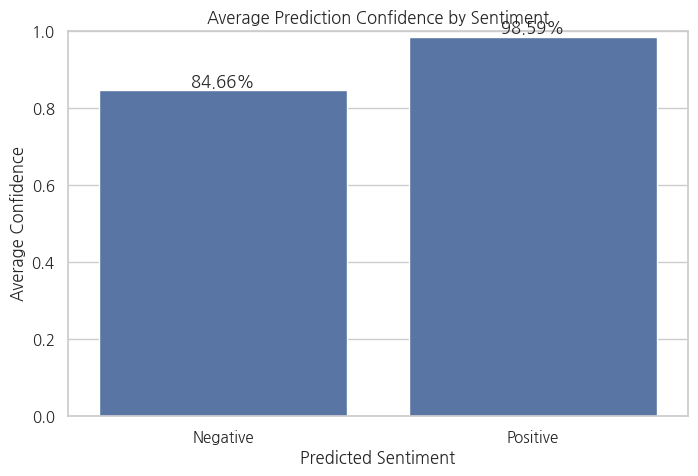

In [82]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=confidence_analysis,
    x="Predicted Sentiment",
    y="Average_Confidence"
)

plt.title("Average Prediction Confidence by Sentiment")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Average Confidence")
plt.ylim(0, 1)

for i, value in enumerate(confidence_analysis["Average_Confidence"]):
    plt.text(i, value + 0.01, f"{value:.2%}", ha="center")

plt.show()

### 6.10 Confidence Analysis – Key Findings

The confidence analysis of 50 sample reviews revealed:

- Positive predictions: 47 reviews with an average confidence of 98.59%.
- Negative predictions: 3 reviews with an average confidence of 84.66%.
- The model demonstrated higher confidence in Positive predictions compared to Negative predictions.

**Key Observation:**

The model showed a strong preference for Positive classifications in this sample. However, confidence scores indicate prediction certainty, not actual correctness. Further validation using manually labeled reviews is required to assess model reliability.

### 6.11 Full Dataset Sentiment Classification

After evaluating the sentiment classification model on a sample of 50 reviews, the model will be applied to the complete dataset of 92,590 Korean customer reviews.

Each review will be classified as Positive or Negative based on its original Korean text.

The predicted sentiment and confidence score will be stored separately without modifying the original review data or rating-based sentiment column.

In [83]:
import pandas as pd
import numpy as np

# Reload original cleaned dataset
df = pd.read_csv("/content/korean_beauty_reviews_cleaned.csv")

print("Dataset Shape:", df.shape)
print("Total Reviews:", len(df))
print("Columns:", df.columns.tolist())

Dataset Shape: (92590, 7)
Total Reviews: 92590
Columns: ['source_id', 'product_name', 'rating', 'skin_type', 'review', 'cleaned_review', 'sentiment']


In [84]:
import torch
from transformers import pipeline

sentiment_classifier = pipeline(
    "text-classification",
    model="WhitePeak/bert-base-cased-Korean-sentiment",
    device=0 if torch.cuda.is_available() else -1
)

print("Sentiment Model Loaded Successfully!")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Sentiment Model Loaded Successfully!


In [85]:
print("Total Reviews:", len(df))
print("Model Loaded:", sentiment_classifier is not None)
print("Device:", sentiment_classifier.device)

Total Reviews: 92590
Model Loaded: True
Device: cpu


In [88]:
from tqdm.auto import tqdm

# Select first 5000 reviews
sample_reviews_5000 = (
    df["cleaned_review"]
    .fillna("")
    .astype(str)
    .iloc[:5000]
    .tolist()
)

all_predictions = []

batch_size = 50

for i in tqdm(range(0, len(sample_reviews_5000), batch_size)):

    review_batch = sample_reviews_5000[i:i + batch_size]

    batch_predictions = sentiment_classifier(
        review_batch,
        truncation=True,
        max_length=512,
        batch_size=8
    )

    all_predictions.extend(batch_predictions)

print("Total Predictions:", len(all_predictions))

  0%|          | 0/100 [00:00<?, ?it/s]

Total Predictions: 5000


In [89]:
text_sentiment_results = pd.DataFrame({
    "Review": sample_reviews_5000,

    "Predicted Sentiment": [
        "Positive" if p["label"] == "LABEL_1" else "Negative"
        for p in all_predictions
    ],

    "Confidence": [
        round(p["score"], 4)
        for p in all_predictions
    ]
})

display(text_sentiment_results.head(10))

,Review,Predicted Sentiment,Confidence
0,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Negative,0.9784
1,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...",Positive,0.9912
2,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...,Positive,0.6741
3,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,Positive,0.9903
4,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...",Positive,0.9920
5,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...,Positive,0.5999
6,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...,Positive,0.9921
7,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...,Positive,0.9275
8,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...,Positive,0.9918
9,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...,Positive,0.9922


In [90]:
print("Total Reviews:", len(text_sentiment_results))

print(
    "Missing Predictions:",
    text_sentiment_results["Predicted Sentiment"].isna().sum()
)

Total Reviews: 5000
Missing Predictions: 0


In [91]:
sentiment_distribution = (
    text_sentiment_results["Predicted Sentiment"]
    .value_counts()
    .reset_index()
)

sentiment_distribution.columns = [
    "Predicted Sentiment",
    "Total Reviews"
]

sentiment_distribution["Percentage"] = (
    sentiment_distribution["Total Reviews"]
    / len(text_sentiment_results) * 100
).round(2)

display(sentiment_distribution)

,Predicted Sentiment,Total Reviews,Percentage
0,Positive,4420,88.4
1,Negative,580,11.6


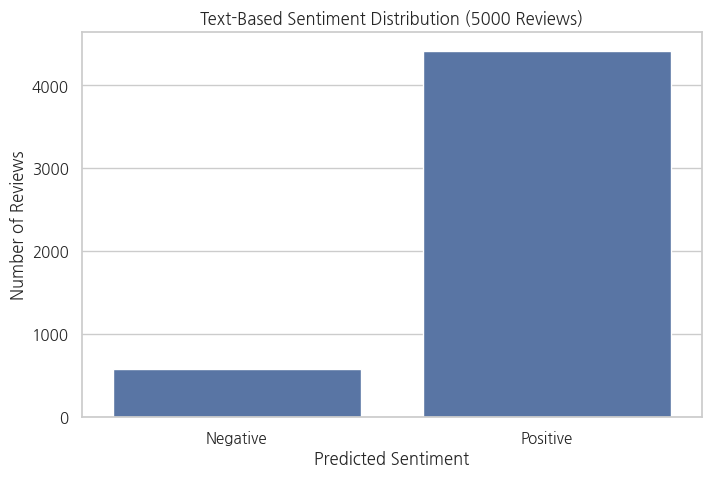

In [92]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=text_sentiment_results,
    x="Predicted Sentiment"
)

plt.title("Text-Based Sentiment Distribution (5000 Reviews)")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

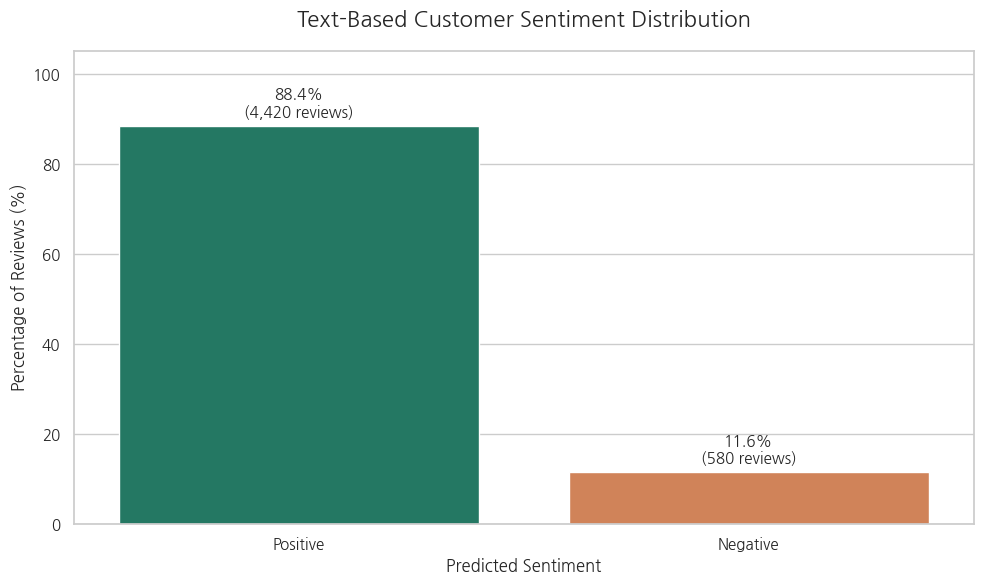

In [95]:

# Text-Based Sentiment Distribution

sentiment_summary = (
    text_sentiment_results["Predicted Sentiment"]
    .value_counts()
    .reindex(["Positive", "Negative"], fill_value=0)
    .reset_index()
)

sentiment_summary.columns = ["Sentiment", "Total Reviews"]

sentiment_summary["Percentage"] = (
    sentiment_summary["Total Reviews"]
    / len(text_sentiment_results) * 100
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=sentiment_summary,
    x="Sentiment",
    y="Percentage",
    hue="Sentiment",
    palette={
        "Positive": "#16866A",
        "Negative": "#E47D45"
    },
    legend=False
)

plt.title(
    "Text-Based Customer Sentiment Distribution",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Predicted Sentiment", fontsize=12)
plt.ylabel("Percentage of Reviews (%)", fontsize=12)

plt.ylim(0, 105)

for i, row in sentiment_summary.iterrows():
    ax.text(
        i,
        row["Percentage"] + 2,
        f'{row["Percentage"]:.1f}%\n({row["Total Reviews"]:,} reviews)',
        ha="center",
        fontsize=11
    )

plt.tight_layout()

plt.savefig(
    "text_sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [94]:
confidence_analysis = (
    text_sentiment_results
    .groupby("Predicted Sentiment")
    .agg(
        Average_Confidence=("Confidence", "mean"),
        Total_Reviews=("Confidence", "count")
    )
    .round(4)
)

display(confidence_analysis)

,Average_Confidence,Total_Reviews
Predicted Sentiment,,
Negative,0.9104,580
Positive,0.9780,4420


## 6.12 Text-Based Sentiment Analysis — Key Findings

The text-based sentiment analysis was performed on a sample of 5,000 Korean beauty product reviews using a pretrained Korean sentiment classification model.

### Key Findings

1. Out of 5,000 reviews, 4,420 (88.4%) were classified as Positive.
2. A total of 580 reviews (11.6%) were classified as Negative.
3. Positive reviews had an average model confidence of 97.80%.
4. Negative reviews had an average model confidence of 91.04%.
5. The results indicate that positive customer opinions were more common than negative opinions in the analyzed sample.

### Business Insights

- The high proportion of positive reviews suggests generally favorable customer opinions about the analyzed beauty products.
- Negative reviews represent opportunities to identify product issues and improve customer satisfaction.
- Businesses can investigate negative feedback to understand concerns related to product quality, skin irritation, hydration, and overall performance.
- Positive feedback can help businesses identify product strengths and customer-preferred features.

### Important Note

This analysis uses actual Korean review text and is different from the rating-based sentiment analysis performed earlier.

The results represent only a sample of 5,000 reviews out of 92,590 total reviews. Model confidence scores do not represent verified prediction accuracy.

# PART 7: NEGATIVE REVIEW ANALYSIS

## 7.1 Objective

To analyze negative customer feedback from Korean beauty product reviews and identify common product-related concerns and areas for improvement.

## Business Questions

1. How many reviews express negative customer opinions?
2. Which products receive the highest number of negative reviews?
3. Which products have a higher percentage of negative feedback?
4. What can businesses learn from negative customer experiences?
5. How can negative feedback help improve product quality and customer satisfaction?

## Analysis Approach

This analysis will use the 5,000 reviews classified in Part 6 through text-based sentiment analysis.

Only reviews predicted as Negative will be selected for further investigation.

The original Korean review text will be preserved.

In [96]:
negative_reviews = text_sentiment_results[
    text_sentiment_results["Predicted Sentiment"] == "Negative"
].copy()

print("Total Negative Reviews:", len(negative_reviews))

display(negative_reviews.head(10))

Total Negative Reviews: 580


,Review,Predicted Sentiment,Confidence
0,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Negative,0.9784
12,왜 이 제품이 그렇게 유명한 지 이제야 깨달은 1인입니다.제 피부가 극 민감성+트러...,Negative,0.9022
15,이주가량 사용해 보았습니다우선 🔸️용기가 펌핑이나 튜브형태가 아니라 위생상 좋지 않...,Negative,0.9076
42,정말 아쉽게도 저와 닥터지 수분크림이 맞지않네요 ᅲᅲ맞는분들은 잘 쓰시던데...일단...,Negative,0.9943
43,"1. 피부타입24세, 지성, 좁쌀, 성인 여드름( 얼굴 외곽선 쪽에만),수분 부족,...",Negative,0.9499
49,성인때는 한번도 안나던 트러블들이 성인되서는 왜 이렇게나는지 ᅲ 한참 음주에 빠졌을...,Negative,0.9353
67,🌷 제형 : 흰끼도는 투명한 젤 제형이에요! 엄청 가볍지는 않고 유분 20프로 + ...,Negative,0.8083
78,몰라요...이제품 항상 구매할때마다 안맞아요.. 늘 인기있는 제품이라 한번씩 사고 ...,Negative,0.9968
79,모든 제품이 그럴 수 있지만 쫌만 더 발라도 저는 트러블이 나더라고요 정말 얇-게 ...,Negative,0.6269
120,저는 여드름이 나는 민감한 피부이고 수분이 부족한 복합성 피부입니다! 요즘 얼굴에 ...,Negative,0.5265


In [97]:
print(df.columns.tolist())

['source_id', 'product_name', 'rating', 'skin_type', 'review', 'cleaned_review', 'sentiment']


In [98]:
negative_reviews = negative_reviews.copy()

negative_reviews["Product Name"] = (
    df.loc[negative_reviews.index, "product_name"].values
)

print("Total Negative Reviews:", len(negative_reviews))

display(
    negative_reviews[
        [
            "Product Name",
            "Review",
            "Predicted Sentiment",
            "Confidence"
        ]
    ].head(10)
)

Total Negative Reviews: 580


,Product Name,Review,Predicted Sentiment,Confidence
0,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Negative,0.9784
12,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),왜 이 제품이 그렇게 유명한 지 이제야 깨달은 1인입니다.제 피부가 극 민감성+트러...,Negative,0.9022
15,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),이주가량 사용해 보았습니다우선 🔸️용기가 펌핑이나 튜브형태가 아니라 위생상 좋지 않...,Negative,0.9076
42,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),정말 아쉽게도 저와 닥터지 수분크림이 맞지않네요 ᅲᅲ맞는분들은 잘 쓰시던데...일단...,Negative,0.9943
43,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),"1. 피부타입24세, 지성, 좁쌀, 성인 여드름( 얼굴 외곽선 쪽에만),수분 부족,...",Negative,0.9499
49,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),성인때는 한번도 안나던 트러블들이 성인되서는 왜 이렇게나는지 ᅲ 한참 음주에 빠졌을...,Negative,0.9353
67,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),🌷 제형 : 흰끼도는 투명한 젤 제형이에요! 엄청 가볍지는 않고 유분 20프로 + ...,Negative,0.8083
78,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),몰라요...이제품 항상 구매할때마다 안맞아요.. 늘 인기있는 제품이라 한번씩 사고 ...,Negative,0.9968
79,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),모든 제품이 그럴 수 있지만 쫌만 더 발라도 저는 트러블이 나더라고요 정말 얇-게 ...,Negative,0.6269
120,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),저는 여드름이 나는 민감한 피부이고 수분이 부족한 복합성 피부입니다! 요즘 얼굴에 ...,Negative,0.5265


In [99]:
negative_product_analysis = (
    negative_reviews
    .groupby("Product Name")
    .agg(
        Negative_Reviews=("Predicted Sentiment", "count"),
        Average_Confidence=("Confidence", "mean")
    )
    .reset_index()
)

negative_product_analysis["Average_Confidence"] = (
    negative_product_analysis["Average_Confidence"].round(4)
)

negative_product_analysis = (
    negative_product_analysis
    .sort_values("Negative_Reviews", ascending=False)
)

print(
    "Products with Negative Reviews:",
    len(negative_product_analysis)
)

display(negative_product_analysis.head(15))

Products with Negative Reviews: 8


,Product Name,Negative_Reviews,Average_Confidence
1,[단독기획] 라운드랩 자작나무 수분크림 더블기획 (80ml+80ml),151,0.9216
3,[오원Pick] 닥터자르트 시카페어 크림(50ml+25ml) 한정세트,133,0.9087
6,"라로슈포제 시카플라스트 밤B5 100ml 기획(+시카 세럼 10ml,에빠끌라폼15ml)",109,0.9002
7,에스트라 아토베리어365 크림 80ml 짝꿍기획 (+하이드로에센스 40ml 증정),83,0.9128
4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),70,0.9028
2,[단독최대용량]밀크터치 서양송악 진정 크림 스페셜세트 (50ml+30ml),16,0.9146
5,[특별기획]프리메라 알파인 베리 워터리 크림 50ml(+크림25ml+필링15ml+에...,13,0.9199
0,[단독][1+1] 크리니크 쏙보습크림 50ml 1+1 기획세트 (+애슝 스티커 증정),5,0.8622


In [100]:
top_negative_products = negative_product_analysis.head(10)

display(top_negative_products)

,Product Name,Negative_Reviews,Average_Confidence
1,[단독기획] 라운드랩 자작나무 수분크림 더블기획 (80ml+80ml),151,0.9216
3,[오원Pick] 닥터자르트 시카페어 크림(50ml+25ml) 한정세트,133,0.9087
6,"라로슈포제 시카플라스트 밤B5 100ml 기획(+시카 세럼 10ml,에빠끌라폼15ml)",109,0.9002
7,에스트라 아토베리어365 크림 80ml 짝꿍기획 (+하이드로에센스 40ml 증정),83,0.9128
4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),70,0.9028
2,[단독최대용량]밀크터치 서양송악 진정 크림 스페셜세트 (50ml+30ml),16,0.9146
5,[특별기획]프리메라 알파인 베리 워터리 크림 50ml(+크림25ml+필링15ml+에...,13,0.9199
0,[단독][1+1] 크리니크 쏙보습크림 50ml 1+1 기획세트 (+애슝 스티커 증정),5,0.8622


In [101]:
# Total reviews for each product in the 5000-review sample

total_product_reviews = (
    df.iloc[:5000]
    .groupby("product_name")
    .size()
    .reset_index(name="Total_Reviews")
)

# Merge negative and total review counts

negative_percentage_analysis = (
    negative_product_analysis
    .merge(
        total_product_reviews,
        left_on="Product Name",
        right_on="product_name",
        how="left"
    )
)

# Calculate negative review percentage

negative_percentage_analysis["Negative_Percentage"] = (
    negative_percentage_analysis["Negative_Reviews"]
    / negative_percentage_analysis["Total_Reviews"] * 100
).round(2)

negative_percentage_analysis = (
    negative_percentage_analysis
    .sort_values("Negative_Percentage", ascending=False)
)

display(
    negative_percentage_analysis[
        [
            "Product Name",
            "Total_Reviews",
            "Negative_Reviews",
            "Negative_Percentage"
        ]
    ]
)

,Product Name,Total_Reviews,Negative_Reviews,Negative_Percentage
7,[단독][1+1] 크리니크 쏙보습크림 50ml 1+1 기획세트 (+애슝 스티커 증정),20,5,25.00
0,[단독기획] 라운드랩 자작나무 수분크림 더블기획 (80ml+80ml),990,151,15.25
2,"라로슈포제 시카플라스트 밤B5 100ml 기획(+시카 세럼 10ml,에빠끌라폼15ml)",739,109,14.75
1,[오원Pick] 닥터자르트 시카페어 크림(50ml+25ml) 한정세트,987,133,13.48
3,에스트라 아토베리어365 크림 80ml 짝꿍기획 (+하이드로에센스 40ml 증정),990,83,8.38
6,[특별기획]프리메라 알파인 베리 워터리 크림 50ml(+크림25ml+필링15ml+에...,156,13,8.33
4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),900,70,7.78
5,[단독최대용량]밀크터치 서양송악 진정 크림 스페셜세트 (50ml+30ml),218,16,7.34


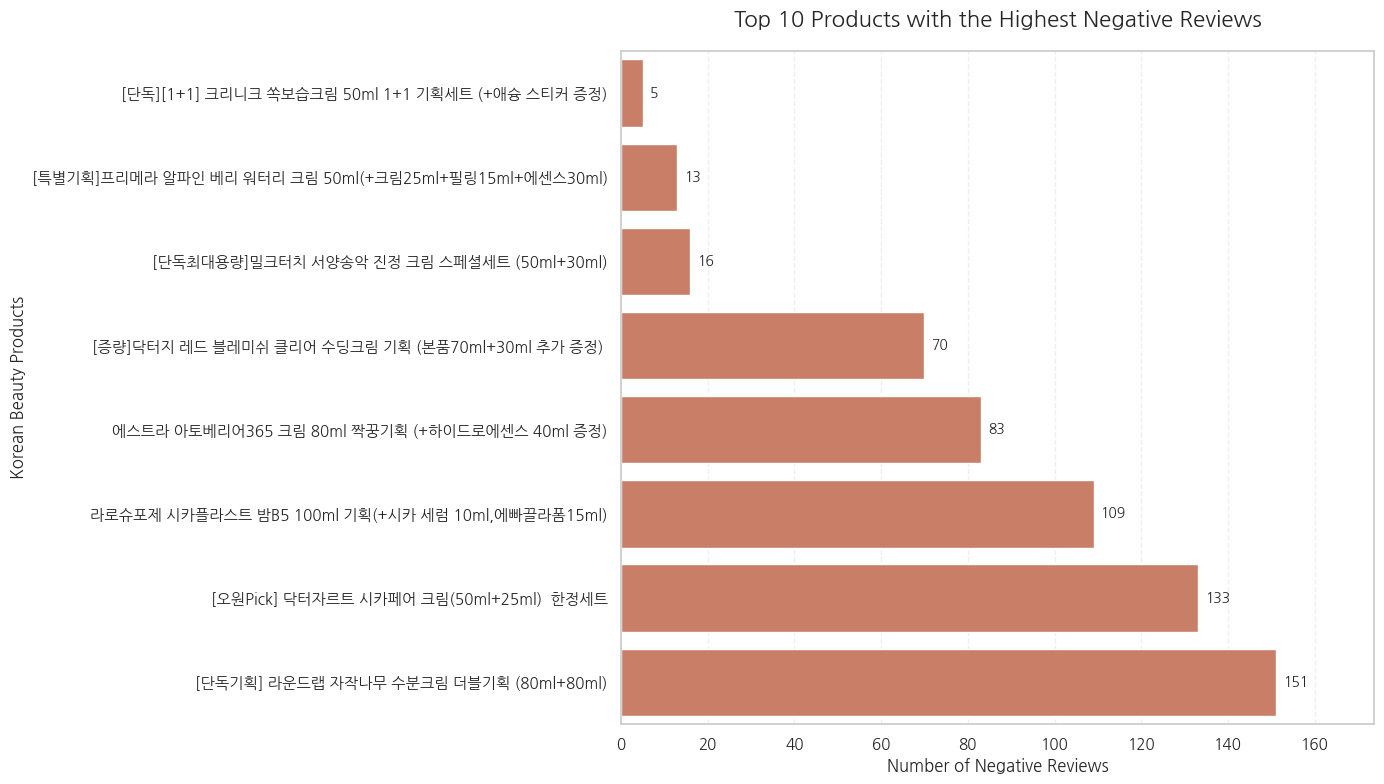

In [103]:
# Select Top 10 Products with Highest Negative Reviews
top_10_negative = (
    negative_product_analysis
    .head(10)
    .sort_values("Negative_Reviews", ascending=True)
)

plt.figure(figsize=(14, 8))

ax = sns.barplot(
    data=top_10_negative,
    x="Negative_Reviews",
    y="Product Name",
    color="#D97757"
)

# Add review counts at the end of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=5,
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Top 10 Products with the Highest Negative Reviews",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Number of Negative Reviews", fontsize=12)
plt.ylabel("Korean Beauty Products", fontsize=12)

plt.xlim(0, top_10_negative["Negative_Reviews"].max() * 1.15)

plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()

## 7.2 Key Findings

The negative review analysis was conducted using 5,000 Korean beauty product reviews classified through text-based sentiment analysis.

### Key Findings

1. A total of 580 reviews were classified as Negative.
2. Round Lab Birch Moisture Cream recorded the highest number of negative reviews (151).
3. Clinique Moisture Surge Cream showed the highest negative review percentage (25.00%), based on only 20 reviews.
4. Round Lab Birch Moisture Cream had 151 negative reviews out of 990 total reviews, representing 15.25%.
5. La Roche-Posay Cicaplast Baume B5 recorded a negative review percentage of 14.75%.
6. Dr.Jart+ Cicapair Cream recorded 133 negative reviews, representing 13.48%.

## 7.3 Business Insights

- Businesses should investigate products with both high negative review counts and high negative review percentages.
- Round Lab, La Roche-Posay, and Dr.Jart+ deserve further investigation because of their comparatively high negative feedback in this sample.
- Products with fewer total reviews should be interpreted carefully because small sample sizes can produce higher percentages.
- Negative customer feedback can help businesses identify potential concerns related to product performance, skin compatibility, texture, and customer expectations.
- Companies can use these findings to prioritize product quality checks and improve customer satisfaction.

### Important Note

This analysis is based on 5,000 reviews and uses model-predicted sentiment labels. The negative predictions are not manually verified customer complaints.

The findings should not be interpreted as a complete evaluation of overall product quality.

# PART 8: KOREAN KEYWORD ANALYSIS

## 8.1 Objective

To identify frequently used Korean words and expressions in customer reviews and understand common customer opinions, product experiences, and concerns.

## Business Questions

1. Which Korean keywords are most frequently used by customers?
2. What words commonly appear in positive reviews?
3. What words commonly appear in negative reviews?
4. What product-related experiences are frequently discussed?
5. How can keyword analysis help businesses understand customer feedback?

## Analysis Approach

This section will use the original Korean review text from the 5,000 reviews analyzed in Part 6.

Keyword frequency will be examined separately for positive and negative reviews.

The original Korean review text will be preserved throughout the analysis.

In [104]:
keyword_data = df.iloc[:5000][
    ["product_name", "review", "cleaned_review"]
].copy()

keyword_data["Predicted Sentiment"] = (
    text_sentiment_results["Predicted Sentiment"].values
)

print("Total Reviews:", len(keyword_data))

print(
    "Missing Reviews:",
    keyword_data["cleaned_review"].isna().sum()
)

display(keyword_data.head(10))

Total Reviews: 5000
Missing Reviews: 0


,product_name,review,cleaned_review,Predicted Sentiment
0,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,Negative
1,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...","👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...",Positive
2,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름...,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...,Positive
3,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,Positive
4,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...","닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...",Positive
5,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...,Positive
6,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...,Positive
7,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...,Positive
8,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...,Positive
9,[증량]닥터지 레드 블레미쉬 클리어 수딩크림 기획 (본품70ml+30ml 추가 증정),2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...,Positive


In [105]:
import re
from collections import Counter

def extract_korean_keywords(text):
    if pd.isna(text):
        return []

    words = re.findall(r"[가-힣]{2,}", str(text))

    return words

keyword_data["Korean Keywords"] = (
    keyword_data["cleaned_review"]
    .apply(extract_korean_keywords)
)

print("Keyword Extraction Completed!")

display(
    keyword_data[
        ["cleaned_review", "Korean Keywords"]
    ].head(10)
)

Keyword Extraction Completed!


,cleaned_review,Korean Keywords
0,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,"[제품은, 정말, 사용해보시라고, 추천드리고싶어요진짜, 좋은, 제품이거든요사춘기때,..."
1,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...","[간단정리, 자극없이, 무난함, 봄여름가을에, 적당한, 수분감, 겨울엔, 두겹, 레..."
2,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...,"[나의, 피부상태, 복합성, 트러블, 조금만, 자극적이면, 피부, 뒤집어짐, 장점,..."
3,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,"[샀어요, 진짜, 닥터지, 최고입니다, 건성분들이, 쓰시기에는, 너무, 빨리, 날아..."
4,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...","[닥터지, 크림은, 워낙, 유명하기도, 하고, 성분이, 순하고, 진정효과가, 좋아서..."
5,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...,"[한줄요약가격, 화장품을, 쓰는, 입장에서는, 가성비, 굿보습, 약간, 건성, 지성..."
6,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...,"[수분크림이, 떨어져서, 살까, 하다가, 닥터지, 수분크림이, 유명하다고, 해서, ..."
7,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...,"[피부타입, 민감성, 수부지, 피부장벽, 무너져서, 얼굴, 뒤집어짐, 총평, 유수분..."
8,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...,"[피부는, 예민하고, 민감한, 편이라, 주로, 사용하는, 제품들은, 약산성, 제품을..."
9,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...,"[통째, 쓰고, 있는, 저의, 인생크림, 건성이라서, 보습이, 강력한, 크림을, 좋..."


In [106]:
korean_stopwords = [
    "그리고", "그래서", "하지만", "정말", "너무",
    "진짜", "그냥", "조금", "매우", "제가",
    "저는", "저도", "이번", "제품", "사용",
    "구매", "때문", "정도", "있는", "없는",
    "같아요", "같습니다", "합니다", "입니다",
    "있어요", "없어요", "했어요", "좋아요"
]

def remove_stopwords(words):
    return [
        word for word in words
        if word not in korean_stopwords
    ]

keyword_data["Filtered Keywords"] = (
    keyword_data["Korean Keywords"]
    .apply(remove_stopwords)
)

print("Stopword Removal Completed!")

display(
    keyword_data[
        ["Korean Keywords", "Filtered Keywords"]
    ].head(10)
)

Stopword Removal Completed!


,Korean Keywords,Filtered Keywords
0,"[제품은, 정말, 사용해보시라고, 추천드리고싶어요진짜, 좋은, 제품이거든요사춘기때,...","[제품은, 사용해보시라고, 추천드리고싶어요진짜, 좋은, 제품이거든요사춘기때, 여드름..."
1,"[간단정리, 자극없이, 무난함, 봄여름가을에, 적당한, 수분감, 겨울엔, 두겹, 레...","[간단정리, 자극없이, 무난함, 봄여름가을에, 적당한, 수분감, 겨울엔, 두겹, 레..."
2,"[나의, 피부상태, 복합성, 트러블, 조금만, 자극적이면, 피부, 뒤집어짐, 장점,...","[나의, 피부상태, 복합성, 트러블, 조금만, 자극적이면, 피부, 뒤집어짐, 장점,..."
3,"[샀어요, 진짜, 닥터지, 최고입니다, 건성분들이, 쓰시기에는, 너무, 빨리, 날아...","[샀어요, 닥터지, 최고입니다, 건성분들이, 쓰시기에는, 빨리, 날아가서, 피부에,..."
4,"[닥터지, 크림은, 워낙, 유명하기도, 하고, 성분이, 순하고, 진정효과가, 좋아서...","[닥터지, 크림은, 워낙, 유명하기도, 하고, 성분이, 순하고, 진정효과가, 좋아서..."
5,"[한줄요약가격, 화장품을, 쓰는, 입장에서는, 가성비, 굿보습, 약간, 건성, 지성...","[한줄요약가격, 화장품을, 쓰는, 입장에서는, 가성비, 굿보습, 약간, 건성, 지성..."
6,"[수분크림이, 떨어져서, 살까, 하다가, 닥터지, 수분크림이, 유명하다고, 해서, ...","[수분크림이, 떨어져서, 살까, 하다가, 닥터지, 수분크림이, 유명하다고, 해서, ..."
7,"[피부타입, 민감성, 수부지, 피부장벽, 무너져서, 얼굴, 뒤집어짐, 총평, 유수분...","[피부타입, 민감성, 수부지, 피부장벽, 무너져서, 얼굴, 뒤집어짐, 총평, 유수분..."
8,"[피부는, 예민하고, 민감한, 편이라, 주로, 사용하는, 제품들은, 약산성, 제품을...","[피부는, 예민하고, 민감한, 편이라, 주로, 사용하는, 제품들은, 약산성, 제품을..."
9,"[통째, 쓰고, 있는, 저의, 인생크림, 건성이라서, 보습이, 강력한, 크림을, 좋...","[통째, 쓰고, 저의, 인생크림, 건성이라서, 보습이, 강력한, 크림을, 좋아하는데..."


In [107]:
all_keywords = [
    word
    for words in keyword_data["Filtered Keywords"]
    for word in words
]

keyword_frequency = Counter(all_keywords)

top_20_keywords = pd.DataFrame(
    keyword_frequency.most_common(20),
    columns=["Korean Keyword", "Frequency"]
)

display(top_20_keywords)

,Korean Keyword,Frequency
0,피부가,1467
1,많이,1332
2,바르고,1221
3,피부,994
4,크림,976
5,피부에,944
6,좋은,794
7,바르면,682
8,이거,625
9,쓰고,602


In [108]:
positive_keyword_data = keyword_data[
    keyword_data["Predicted Sentiment"] == "Positive"
].copy()

print("Total Positive Reviews:", len(positive_keyword_data))

display(
    positive_keyword_data[
        ["cleaned_review", "Filtered Keywords"]
    ].head(10)
)

Total Positive Reviews: 4420


,cleaned_review,Filtered Keywords
1,"👉🏻 간단정리! - good! : 자극없이 무난함, 봄여름가을에 적당한 수분감, 겨...","[간단정리, 자극없이, 무난함, 봄여름가을에, 적당한, 수분감, 겨울엔, 두겹, 레..."
2,❤️나의 피부상태: 복합성+트러블 조금만 자극적이면 피부 뒤집어짐;💜장점: 여드름 ...,"[나의, 피부상태, 복합성, 트러블, 조금만, 자극적이면, 피부, 뒤집어짐, 장점,..."
3,또 샀어요!!!! 진짜 닥터지 최고입니다.. 건성분들이 쓰시기에는 너무 빨리 날아가...,"[샀어요, 닥터지, 최고입니다, 건성분들이, 쓰시기에는, 빨리, 날아가서, 피부에,..."
4,"닥터지 크림은 워낙 유명하기도 하고,성분이 순하고 진정효과가 좋아서 꾸준히 구매해왔...","[닥터지, 크림은, 워낙, 유명하기도, 하고, 성분이, 순하고, 진정효과가, 좋아서..."
5,#한줄요약가격: 화장품을 잘 안 쓰는 내 입장에서는 가성비 굿보습: 약간 건성~지성...,"[한줄요약가격, 화장품을, 쓰는, 입장에서는, 가성비, 굿보습, 약간, 건성, 지성..."
6,수분크림이 다 떨어져서 뭐 살까 하다가 닥터지 수분크림이 유명하다고 해서 구매했어요...,"[수분크림이, 떨어져서, 살까, 하다가, 닥터지, 수분크림이, 유명하다고, 해서, ..."
7,✔️피부타입: 민감성 수부지 피부장벽 무너져서 얼굴 뒤집어짐⭐️총평➖유수분밸런스를 ...,"[피부타입, 민감성, 수부지, 피부장벽, 무너져서, 얼굴, 뒤집어짐, 총평, 유수분..."
8,피부는 예민하고 민감한 편이라 주로 사용하는 제품들은 약산성 PH제품을 선호하는 편...,"[피부는, 예민하고, 민감한, 편이라, 주로, 사용하는, 제품들은, 약산성, 제품을..."
9,2통째 쓰고 있는 저의 인생크림👍건성이라서 보습이 강력한 크림을 좋아하는데 이 크림...,"[통째, 쓰고, 저의, 인생크림, 건성이라서, 보습이, 강력한, 크림을, 좋아하는데..."
10,수분크힘 추천 받아서 고민하다가 쿠폰도 사용해볼겸 한번 구매 해봤습니다!☺️일단 제...,"[수분크힘, 추천, 받아서, 고민하다가, 쿠폰도, 사용해볼겸, 한번, 해봤습니다, ..."


In [109]:
positive_keywords = [
    word
    for words in positive_keyword_data["Filtered Keywords"]
    for word in words
]

positive_keyword_frequency = Counter(positive_keywords)

top_20_positive_keywords = pd.DataFrame(
    positive_keyword_frequency.most_common(20),
    columns=["Korean Keyword", "Frequency"]
)

display(top_20_positive_keywords)

,Korean Keyword,Frequency
0,피부가,1305
1,많이,1178
2,바르고,1088
3,크림,875
4,피부,873
5,피부에,859
6,좋은,739
7,바르면,593
8,쓰고,544
9,있어서,532


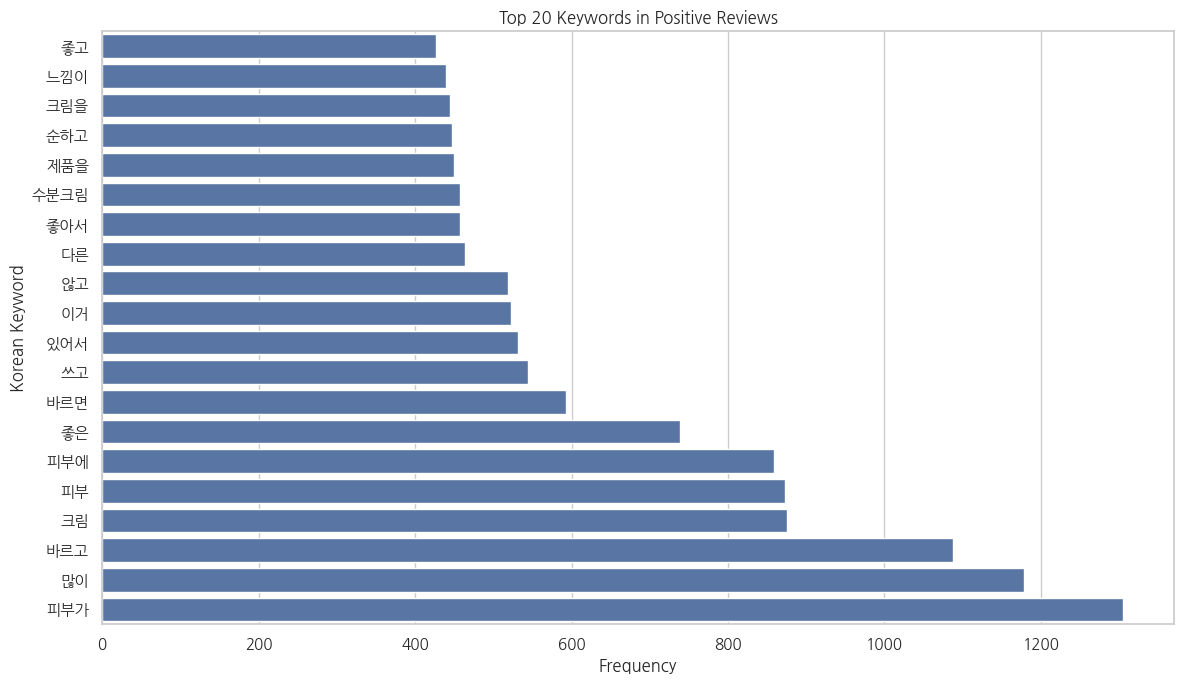

In [110]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_20_positive_keywords.sort_values("Frequency"),
    x="Frequency",
    y="Korean Keyword"
)

plt.title("Top 20 Keywords in Positive Reviews")
plt.xlabel("Frequency")
plt.ylabel("Korean Keyword")

plt.tight_layout()
plt.show()

In [111]:
negative_keyword_data = keyword_data[
    keyword_data["Predicted Sentiment"] == "Negative"
].copy()

print("Total Negative Reviews:", len(negative_keyword_data))

display(
    negative_keyword_data[
        ["cleaned_review", "Filtered Keywords"]
    ].head(10)
)

Total Negative Reviews: 580


,cleaned_review,Filtered Keywords
0,Dr.G 제품은 정말 사용해보시라고 추천드리고싶어요진짜 좋은 제품이거든요사춘기때 여...,"[제품은, 사용해보시라고, 추천드리고싶어요진짜, 좋은, 제품이거든요사춘기때, 여드름..."
12,왜 이 제품이 그렇게 유명한 지 이제야 깨달은 1인입니다.제 피부가 극 민감성+트러...,"[제품이, 그렇게, 유명한, 이제야, 깨달은, 인입니다, 피부가, 민감성, 트러블,..."
15,이주가량 사용해 보았습니다우선 🔸️용기가 펌핑이나 튜브형태가 아니라 위생상 좋지 않...,"[이주가량, 사용해, 보았습니다우선, 용기가, 펌핑이나, 튜브형태가, 아니라, 위생..."
42,정말 아쉽게도 저와 닥터지 수분크림이 맞지않네요 ᅲᅲ맞는분들은 잘 쓰시던데...일단...,"[아쉽게도, 저와, 닥터지, 수분크림이, 맞지않네요, 맞는분들은, 쓰시던데, 일단,..."
43,"1. 피부타입24세, 지성, 좁쌀, 성인 여드름( 얼굴 외곽선 쪽에만),수분 부족,...","[피부타입, 지성, 좁쌀, 성인, 여드름, 얼굴, 외곽선, 쪽에만, 수분, 부족, ..."
49,성인때는 한번도 안나던 트러블들이 성인되서는 왜 이렇게나는지 ᅲ 한참 음주에 빠졌을...,"[성인때는, 한번도, 안나던, 트러블들이, 성인되서는, 이렇게나는지, 한참, 음주에..."
67,🌷 제형 : 흰끼도는 투명한 젤 제형이에요! 엄청 가볍지는 않고 유분 20프로 + ...,"[제형, 흰끼도는, 투명한, 제형이에요, 엄청, 가볍지는, 않고, 유분, 프로, 수..."
78,몰라요...이제품 항상 구매할때마다 안맞아요.. 늘 인기있는 제품이라 한번씩 사고 ...,"[몰라요, 이제품, 항상, 구매할때마다, 안맞아요, 인기있는, 제품이라, 한번씩, ..."
79,모든 제품이 그럴 수 있지만 쫌만 더 발라도 저는 트러블이 나더라고요 정말 얇-게 ...,"[모든, 제품이, 그럴, 있지만, 쫌만, 발라도, 트러블이, 나더라고요, 바르면, ..."
120,저는 여드름이 나는 민감한 피부이고 수분이 부족한 복합성 피부입니다! 요즘 얼굴에 ...,"[여드름이, 나는, 민감한, 피부이고, 수분이, 부족한, 복합성, 피부입니다, 요즘..."


In [112]:
negative_keywords = [
    word
    for words in negative_keyword_data["Filtered Keywords"]
    for word in words
]

negative_keyword_frequency = Counter(negative_keywords)

top_20_negative_keywords = pd.DataFrame(
    negative_keyword_frequency.most_common(20),
    columns=["Korean Keyword", "Frequency"]
)

display(top_20_negative_keywords)

,Korean Keyword,Frequency
0,피부가,162
1,많이,154
2,바르고,133
3,피부,121
4,이거,103
5,크림,101
6,바르면,89
7,피부에,85
8,엄청,77
9,근데,75


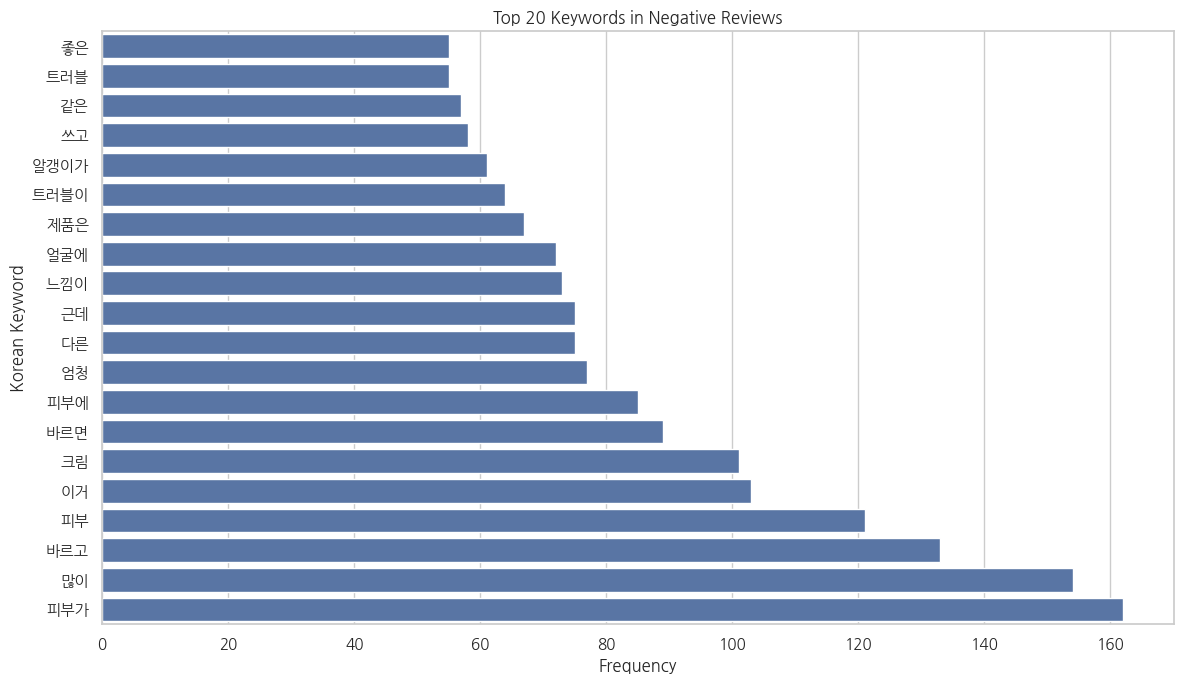

In [113]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_20_negative_keywords.sort_values("Frequency"),
    x="Frequency",
    y="Korean Keyword"
)

plt.title("Top 20 Keywords in Negative Reviews")
plt.xlabel("Frequency")
plt.ylabel("Korean Keyword")

plt.tight_layout()
plt.show()

In [114]:
positive_top_words = set(
    top_20_positive_keywords["Korean Keyword"]
)

negative_top_words = set(
    top_20_negative_keywords["Korean Keyword"]
)

common_keywords = positive_top_words.intersection(
    negative_top_words
)

comparison_keywords = pd.DataFrame({
    "Common Korean Keywords": sorted(common_keywords)
})

print("Common Keywords in Positive and Negative Reviews:",
      len(comparison_keywords))

display(comparison_keywords)

Common Keywords in Positive and Negative Reviews: 12


,Common Korean Keywords
0,느낌이
1,다른
2,많이
3,바르고
4,바르면
5,쓰고
6,이거
7,좋은
8,크림
9,피부


## 8.2 Key Findings

The Korean keyword analysis was conducted using 5,000 customer reviews, including positive and negative reviews.

### Positive Keyword Findings

- Positive reviews frequently contained expressions such as 좋은, 순하고, and 좋아서.
- Customers commonly discussed product gentleness, moisturizing experience, and overall product usage.

### Negative Keyword Findings

- Negative reviews frequently contained skin-related words such as 피부가 and 피부.
- Keywords such as 트러블 and 알갱이가 appeared frequently in negative reviews.
- These words indicate potential areas for further investigation, including skin compatibility, breakouts, and product texture.

### Business Insights

- Businesses should monitor customer feedback related to skin compatibility and product texture.
- Positive feedback can help identify product features customers appreciate.
- Negative feedback can help identify potential product improvement opportunities.
- Keyword analysis can support product development and customer satisfaction strategies.

### Important Note

This analysis uses basic Korean word extraction and frequency counting.

Korean grammatical endings and particles have not been fully normalized. Therefore, keyword frequencies represent exploratory patterns rather than complete semantic interpretations.

The analysis is based on 5,000 reviews and model-predicted sentiment labels.

# PART 9: FINAL BUSINESS INSIGHTS

## 9.1 Objective

To summarize the findings from all analysis sections and develop meaningful business insights and recommendations based on Korean beauty product customer reviews.

## 9.2 Key Business Questions

1. What are the overall customer satisfaction levels?
2. Which products demonstrate strong customer performance?
3. How do customer experiences differ across skin types?
4. What are the major concerns expressed in negative reviews?
5. What do positive and negative Korean keywords reveal about customer experiences?
6. How can businesses use these findings to improve product quality and customer satisfaction?



## 9.3 Overall Project Findings

### 1. Customer Satisfaction

- The dataset contains 92,590 customer reviews.
- The overall average product rating is 4.72 out of 5.
- Rating-based sentiment analysis identified 94.43% Positive, 4.16% Neutral, and 1.41% Negative reviews.
- Text-based sentiment analysis of a separate 5,000-review sample classified 88.4% as Positive and 11.6% as Negative.

### 2. Product Performance

- A total of 351 unique products were analyzed.
- 115 products achieved an average rating of at least 4.70 with at least 100 reviews.
- CKD Retinocollagen Low Molecular 300 Cream achieved an average rating of 4.96 across 990 reviews.
- DR. DAROOM Barrier Cream Special Offer achieved an average rating of 4.98 across 228 reviews.

### 3. Skin Type Analysis

- Combination Skin, Dry Skin, and Oily Skin were among the major identified skin categories.
- Dry Skin recorded an average rating of 4.76 across 7,052 reviews.
- Combination Skin recorded an average rating of 4.73 across 12,131 reviews.
- Oily Skin recorded an average rating of 4.71 across 3,245 reviews.
- A large proportion of reviews had Unknown skin type information.

### 4. Negative Review Analysis

- 580 out of 5,000 reviews were classified as Negative through text-based sentiment analysis.
- Round Lab Birch Moisture Cream recorded the highest negative review count, with 151 reviews.
- Clinique Moisture Surge Cream had the highest negative review percentage (25%), but this was based on only 20 reviews.
- Skin compatibility, breakouts, and product texture appeared as potential areas of customer concern.

### 5. Korean Keyword Analysis

- Positive reviews frequently included words such as 좋은, 순하고, and 좋아서.
- Negative reviews frequently included words such as 트러블 and 알갱이가.
- Skin-related expressions appeared frequently in both positive and negative reviews.
- These keywords provide useful clues about customer experiences and product expectations.


## 9.4 Business Recommendations

### 1. Improve Product Quality

Businesses should investigate recurring negative customer feedback and identify possible product-related concerns.

### 2. Focus on Skin Compatibility

Product development teams should consider different skin types and customer experiences when developing skincare products.

### 3. Monitor Negative Feedback

Companies should regularly monitor negative reviews to identify potential concerns related to skin irritation, breakouts, texture, and product performance.

### 4. Identify Successful Product Features

Businesses should study highly rated products to understand which product characteristics contribute to positive customer experiences.

### 5. Improve Customer-Centric Marketing

Frequently mentioned positive product features can be used to develop more relevant product descriptions and marketing strategies.

### 6. Use Text-Based Sentiment Analysis

Businesses can use sentiment classification and Korean keyword analysis to monitor customer opinions beyond numerical product ratings.

## 9.5 Project Limitations

1. Text-based sentiment analysis was performed on a sample of 5,000 reviews rather than the complete dataset of 92,590 reviews.
2. The pretrained sentiment model uses only Positive and Negative classifications and does not provide a Neutral category.
3. Model predictions have not been manually validated, so confidence scores should not be interpreted as prediction accuracy.
4. Basic Korean keyword extraction does not fully handle Korean grammatical structures and word endings.
5. A large number of reviews contain Unknown skin type information, limiting detailed skin-type comparisons.
6. Product-level negative review comparisons are based on the analyzed 5,000-review sample and should not be treated as complete product quality rankings.


## 9.6 Final Conclusion

This project analyzed 92,590 Korean beauty product customer reviews to understand customer satisfaction, product performance, skin type preferences, and customer feedback.

The analysis combined rating-based evaluation, exploratory data analysis, product comparisons, text-based sentiment classification, negative review investigation, and Korean keyword frequency analysis.

The findings indicate generally high customer satisfaction based on product ratings. However, text-based analysis also identified negative customer experiences and potential areas for product improvement.

By combining numerical ratings with customer review text, businesses can gain a broader understanding of customer preferences, identify product strengths, investigate customer concerns, and make more informed product development and marketing decisions.

Overall, this project demonstrates how data analytics and natural language processing can support customer-centric decision-making in the Korean beauty industry.